# Introduction to Medical Image Analysis - Mini Project

## Segmentation of lungs from X-ray using basic image processing techniques

Emilia Zabrzanska, Healthcare Data Science CDT, Michaelmas 2026

### The Task

Segment lungs by creating a binary image from a chest X-ray using:

- Segmentation algorithms (thresholding)
- Image filtering algorithms
- Morphological operations

### My approach

I have decided to split this project into the following steps:

- Visualising the data and decide if any preprocessing is necessary, like downsizing, centering or rotation etc.
- Threshold and compare to the ground truth to see what thresholding alone can and cannot do.
- Analyse any failures of thresholding and use these to motivate each filtering and morphological step, added one at a time.
- Run the completed pipeline on every normal and TB case.
- Describe lung texture with GLCM features and classification.

To begin, I import all packages used throughout the notebook and create folders for the figures
(used in the slides) and the result tables.

In [109]:
# used for setting a constant data path
import os
from pathlib import Path

# used for dataframes, numerical operations, and plotting
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# used for image processing and statistical analysis
from scipy import ndimage as ndi
from scipy.stats import mannwhitneyu

# used for image processing and feature extraction
from skimage import io, util, transform, filters, morphology, measure
from skimage.segmentation import clear_border
from skimage.feature import graycomatrix, graycoprops
from skimage.filters import threshold_multiotsu

# used for machine learning and model evaluation
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score

# create output folders if they don't exist
os.makedirs('figures', exist_ok=True)
os.makedirs('results', exist_ok=True)

# set constant seed for reproducibility (my birthday!)
SEED = 2909

## PART 1: Preparing Imaging Data

We first begin by setting the data paths for all images and masks. 

Then, we want to see how many of the images in the dataset are labelled as 'normal' and 'TB'. 

In [ ]:
# paths to the x-rays and left/right lung masks
DATA_DIR  = Path('data/MontgomerySet')
IMAGE_DIR = DATA_DIR / 'CXR_png'
LEFT_DIR  = DATA_DIR / 'ManualMask' / 'leftMask'
RIGHT_DIR = DATA_DIR / 'ManualMask' / 'rightMask'

# sort images based on names
all_cases = sorted(p.name for p in IMAGE_DIR.glob('*.png'))

# split into normal and TB cases 
normal_cases = [n for n in all_cases if int(Path(n).stem[-1]) == 0]
tb_cases     = [n for n in all_cases if int(Path(n).stem[-1]) == 1]

print(f'Total images : {len(all_cases)}')
print(f'Normal       : {len(normal_cases)}')
print(f'TB           : {len(tb_cases)}')

Total images : 138
Normal       : 80
TB           : 58


We now want to load an image and check the size and data type. 

In [3]:
# select first x-ray in normal subset
first = normal_cases[0]
raw   = io.imread(IMAGE_DIR / first)

# print metadata
print(f'File        : {first}')
print(f'Shape       : {raw.shape}')
print(f'Dtype       : {raw.dtype}')
print(f'Value range : [{raw.min()}, {raw.max()}]')
print(f'Megapixels  : {raw.size / 1e6:.1f}')

File        : MCUCXR_0001_0.png
Shape       : (4020, 4892)
Dtype       : uint8
Value range : [0, 255]
Megapixels  : 19.7


We can see that the original data is very large, meaning that filtering and morphoogy could be very slow, so I chose to downsize everything to $512 \times 512$. 

Before doing this, I want to check the raw data across the dataset, to check for any inconsistencies in orientation, framing, rotation etc. 

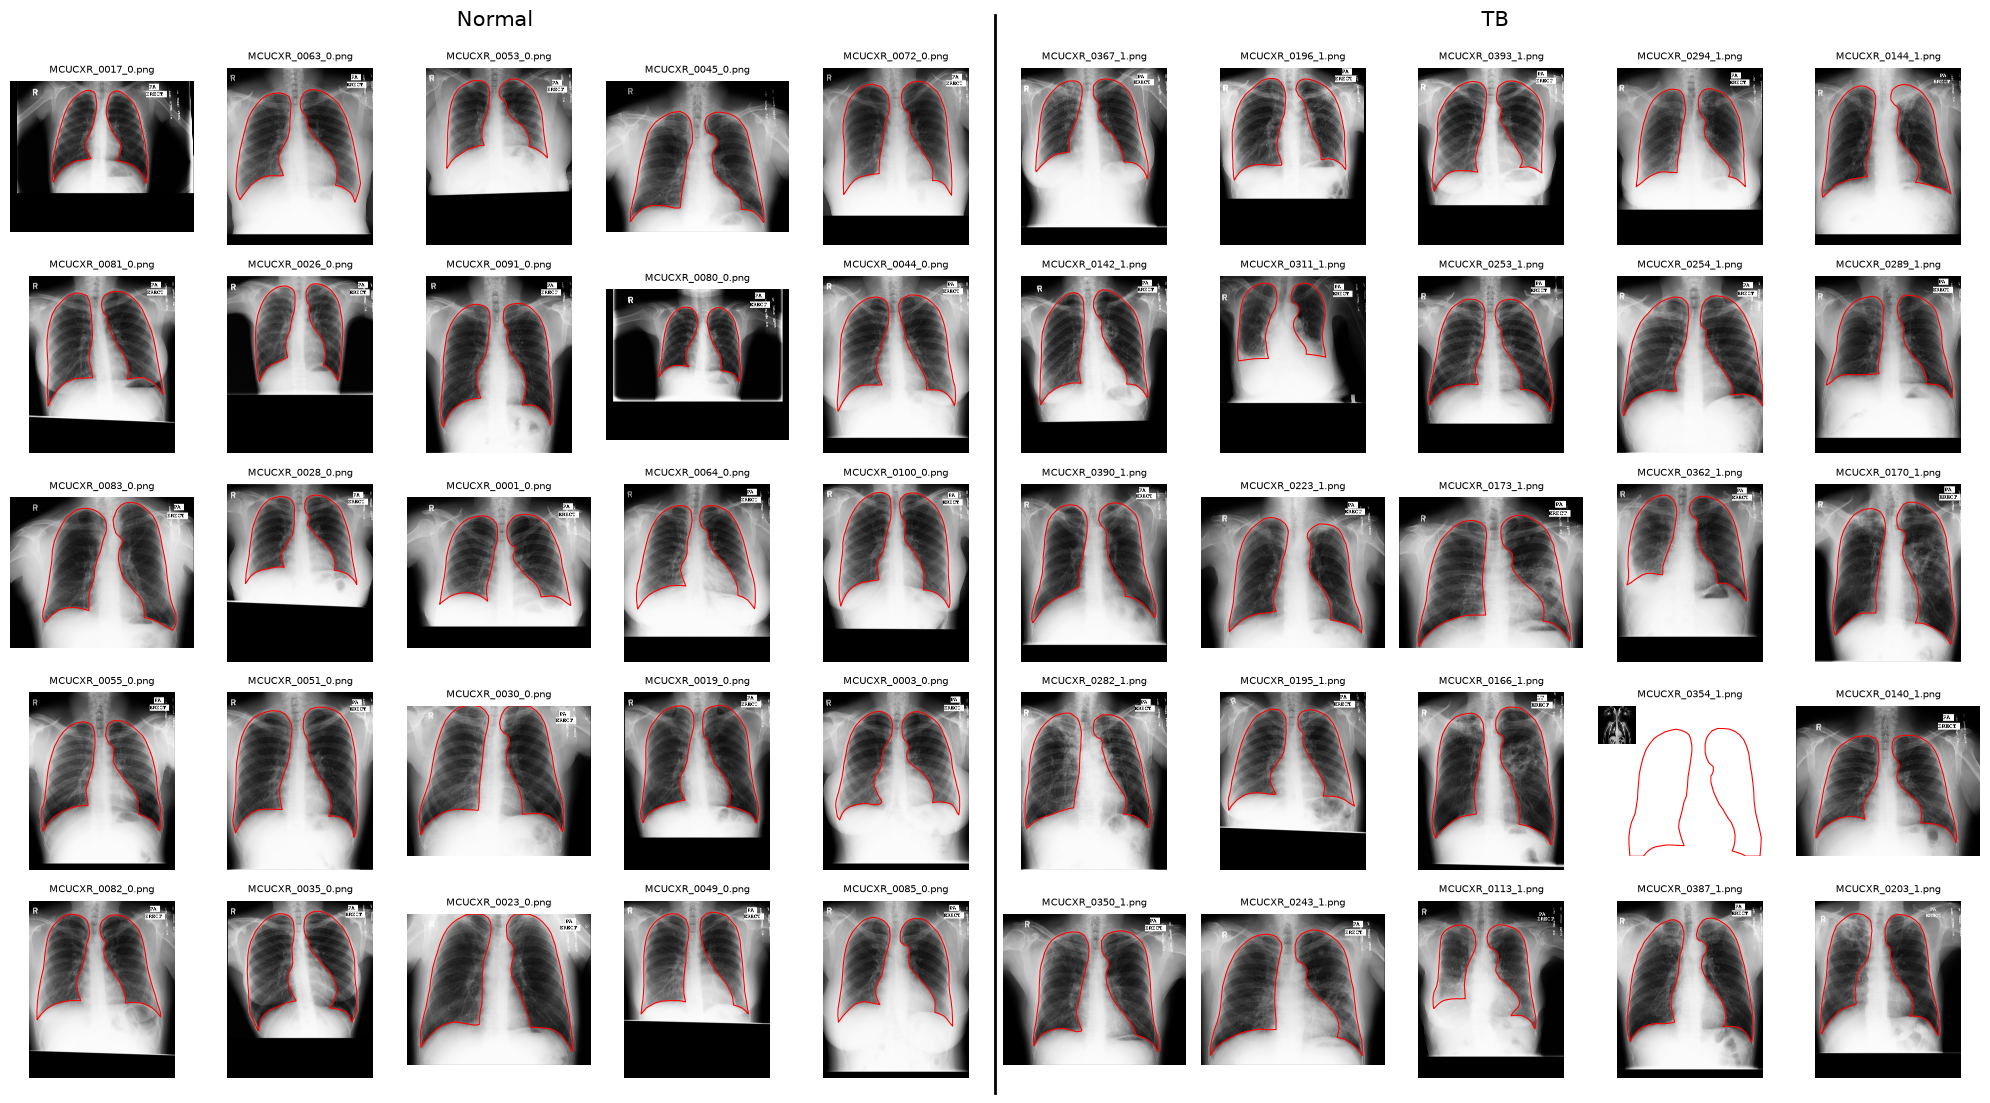

In [4]:
# choose 25 random cases from each class
rng        = np.random.default_rng(SEED)
normal_set = rng.choice(normal_cases, 25, replace=False)
tb_set     = rng.choice(tb_cases, 25, replace=False)

# plot all in a grid
fig, axes = plt.subplots(5, 10, figsize=(20, 11))

# place normal on left, TB on right
for grid, cases in [(axes[:, :5], normal_set), (axes[:, 5:], tb_set)]:

    # loop through each axis, using zip to pair with case names
    for ax, name in zip(grid.ravel(), cases):

        # read x-ray and masks
        xray = io.imread(IMAGE_DIR / name, as_gray=True)
        mask = (io.imread(LEFT_DIR / name) > 0) | (io.imread(RIGHT_DIR / name) > 0)

        # plot x-ray with mask outline in red
        ax.imshow(xray, cmap='gray')
        ax.contour(mask, levels=[0.5], colors='r', linewidths=0.75)
        ax.set_title(name, fontsize=7)
        ax.axis('off')

plt.tight_layout(rect=[0, 0, 1, 0.96])

# show class labels above each grid
fig.text(0.25, 0.97, 'Normal', ha='center', fontsize=15)
fig.text(0.75, 0.97, 'TB', ha='center', fontsize=15)

# add veritcal line between grids
fig.add_artist(plt.Line2D([0.5, 0.5], [0, 0.98], color='k', linewidth=2))

plt.savefig('figures/fig_1_raw_grid.pdf', bbox_inches='tight')
plt.show()

We can see that the data looks good overall, with all 50 of the sampled X-rays having a consistent orientation, and the masks align with the lungs. Several images contain black borders (0017, 0053, 0026, 0028, 0019, 0049, 0196, 0294, 0080, etc.) which may cause failures in the pipeline. 

`MCUCXR_0354_1.png` is a clear outlier, as the X-ray does not match the mask size, so I chose to inspect this more clearly, and check if any other scans do not match the mask size. 

In [ ]:
# compare x-ray and mask size for odd case
name = 'MCUCXR_0354_1.png'
print(f'X-ray : {io.imread(IMAGE_DIR / name).shape}')
print(f'Left  : {io.imread(LEFT_DIR / name).shape}')
print(f'Right : {io.imread(RIGHT_DIR / name).shape}')

# list cases where x-ray and mask sizes differ
for name in all_cases:
    if io.imread(IMAGE_DIR / name).shape != io.imread(LEFT_DIR / name).shape:
        print(name)

X-ray : (1024, 1024, 4)
Left  : (4020, 4892)
Right : (4020, 4892)
MCUCXR_0354_1.png


The outlier seems to be an X-ray with dimensions differing from the rest of the dataset, so I chose to exclude it from the pipeline. 

In [7]:
EXCLUDE = ['MCUCXR_0354_1.png']

# remove from every case list
all_cases    = [n for n in all_cases if n not in EXCLUDE]
normal_cases = [n for n in normal_cases if n not in EXCLUDE]
tb_cases     = [n for n in tb_cases if n not in EXCLUDE]

print(f'Total images : {len(all_cases)}')
print(f'Normal       : {len(normal_cases)}')
print(f'TB           : {len(tb_cases)}')

Total images : 137
Normal       : 80
TB           : 57


We can now move onto downsampling, and as suggested in the lectures, we need to blur (using a low pass filter such as Gaussian) first to prevent aliasing, which is a visual distortion where high-frequency detail creates jagged results. 

The masks contain labels for each pixel, classifying them as 'lung' or 'not lung'. If the masks were resized in the same way as the X-ray, pixels on the edge would be averaged with their neighbours and produce values of 0.5, which are not valid in this case. Instead, we resize them with nearest neighbour set to `order=0`, which copies the value of the closest original pixel. 

Since we segment the lungs together, I also chose to combine the left and right masks into one. 

In [8]:
# set constant size for all images and masks
IMAGE_SIZE = (512, 512)

# define loading function for x-ray and mask
def load_case(filename, size=IMAGE_SIZE):

    """
    Load one x-ray and the combined ground-truth lung mask, resizing both.
    """

    # read x-ray and convert to decimals, converting to greyscale to ensure 2D array
    image = util.img_as_float(io.imread(IMAGE_DIR / filename, as_gray=True))

    # shrink image with anti-aliasing to avoid aliasing
    image = transform.resize(image, size, anti_aliasing=True)

    # read masks and convert to binary, converting to greyscale to ensure 2D array
    left  = io.imread(LEFT_DIR / filename, as_gray=True) > 0
    right = io.imread(RIGHT_DIR / filename, as_gray=True) > 0

    # combine into one mask
    mask = left | right

    # shrink to same size as image
    mask = transform.resize(mask, size, order=0, anti_aliasing=False) > 0.5

    return image, mask

In [9]:
# check the function on the first case
image, mask = load_case(first)

print(f'Resized image : {image.shape}, range [{image.min():.2f}, {image.max():.2f}]')
print(f'Resized mask  : {mask.shape}, {mask.sum()} lung pixels')

Resized image : (512, 512), range [0.00, 1.00]
Resized mask  : (512, 512), 63369 lung pixels


The test image and mask is of the correct dimensions, so we now visualise the same images after downsampling to check if everything remains matched up. 

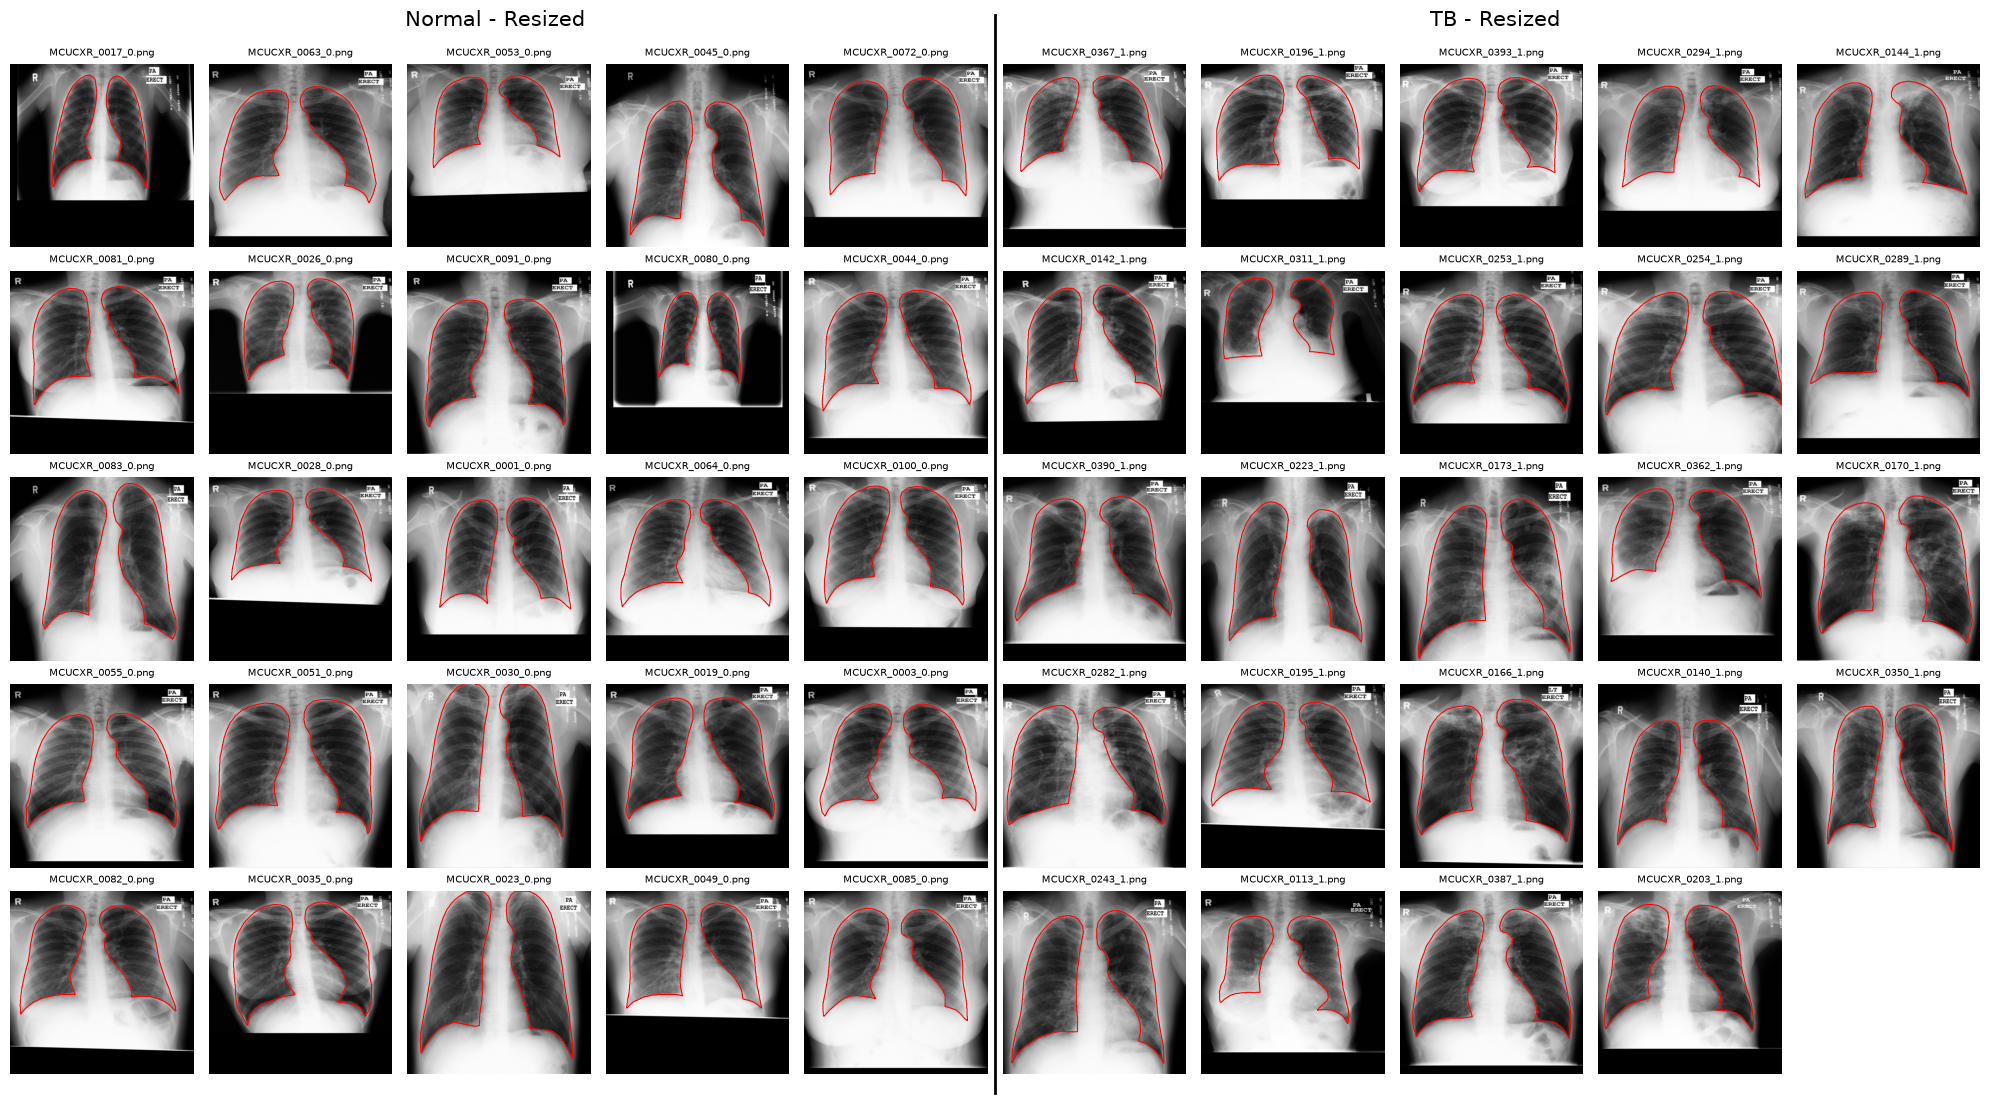

In [11]:
# same cases as raw grid, without excluded case
normal_show = [n for n in normal_set if n not in EXCLUDE]
tb_show     = [n for n in tb_set if n not in EXCLUDE]

fig, axes = plt.subplots(5, 10, figsize=(20, 11))

# hide axes so empty panel stays blank
for ax in axes.ravel():
    ax.axis('off')

# normal on left, tb on right 
for grid, cases in [(axes[:, :5], normal_show), (axes[:, 5:], tb_show)]:

    # loop through each axis, using zip to pair with case names
    for ax, name in zip(grid.ravel(), cases):

        # resize x-ray and combined mask
        image, mask = load_case(name)

        # plot x-ray with lung mask
        ax.imshow(image, cmap='gray')
        ax.contour(mask, levels=[0.5], colors='r', linewidths=0.75)
        ax.set_title(name, fontsize=7)

plt.tight_layout(rect=[0, 0, 1, 0.96])

# label cases
fig.text(0.25, 0.97, 'Normal - Resized', ha='center', fontsize=15)
fig.text(0.75, 0.97, 'TB - Resized', ha='center', fontsize=15)

# add veritcal line between grids
fig.add_artist(plt.Line2D([0.5, 0.5], [0, 0.98], color='k', linewidth=2))

plt.savefig('figures/fig_1_resized_grid.pdf', bbox_inches='tight')
plt.show()

After resizing, every image is $512 \times 512$ and the ground-truth outlines still align with the lungs in all 49 cases. 

Because the original images have different aspect ratios, resizing to a square stretches some of them, especially the wider images (e.g. 0017, 0045, 0080), where the lungs now look narrower.

## PART 2: Thresholding

A threshold $t$ splits pixels into two groups, and since the lungs are mostly a dark area of the scan, we can take the threshold to be lung $=$ pixels with intensity below $t$, but need to be able to select an appropriate value for $t$. 

To compare choices, we can score the mask created against the ground truth (step 7 of the instructions), using the Dice coefficient, which measures overlap between two masks:

$$\text{Dice} = \frac{2|A\cap B|}{|A|+|B|}$$

The score will be 1 for identical masks and 0 for no overlap.

In [21]:
def dice(pred, truth):

    """
    Dice coefficient between two binary masks.
    """

    # find overlap by counting pixels where both masks are True
    overlap = np.logical_and(pred, truth).sum()

    # find total number of pixels in both masks
    total   = pred.sum() + truth.sum()

    # two empty masks count as a perfect match
    return 2 * overlap / total if total > 0 else 1.0

### Supervised thresholding

To pick a sensible value for $t$, we plot the histogram of pixel intensities for one normal case, which shows how many pixels there are at each brightness. Since the lungs are filled with air, we expect them to form a peak at the dark end of the histogram, separated from the brighter peak of bone and soft tissue.

$t$ can then be chosen by picking the mean pixel intensity, or by looking at the histogram and manually selecting a value that lies in between the dark lung peak and the bright tissue peak. 

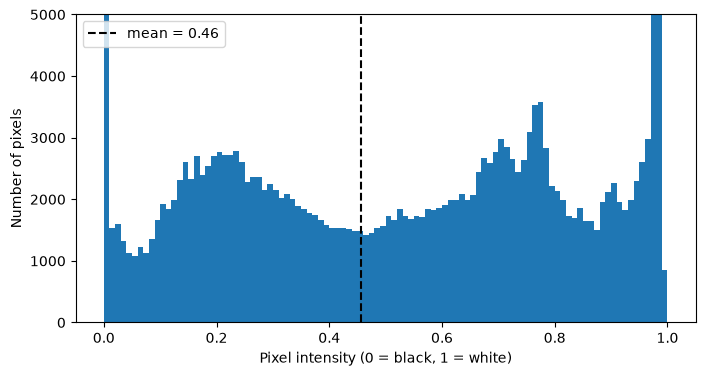

In [22]:
# choose one normal case
image, gt = load_case(normal_cases[0])

# find mean pixel intensity
t_mean = image.mean()

# plot histogram of pixel intensity
plt.figure(figsize=(8, 4))

plt.hist(image.ravel(), bins=100, range=(0, 1))
plt.axvline(t_mean, color='k', ls='--', label=f'mean = {t_mean:.2f}')

# cap y-axis so spike at 0 doesn't hide the shape of the histogram
plt.ylim(0, 5000)

plt.xlabel('Pixel intensity (0 = black, 1 = white)')
plt.ylabel('Number of pixels')
plt.legend()

plt.savefig('figures/fig_2_histogram.pdf', bbox_inches='tight')
plt.show()

The histogram shows a large spike at 0 from the black band at the bottom of the images and a smaller spike near 1 from saturated labels and bone, with the y-axis capped to allow the rest of the distribution to be seen clearly. I chose $t$ = 0.40 by eye in this dip. The mean (0.46) also falls near the dip, but only because the dark and bright spikes roughly cancel out, so it would not be reliable on images with larger black borders.

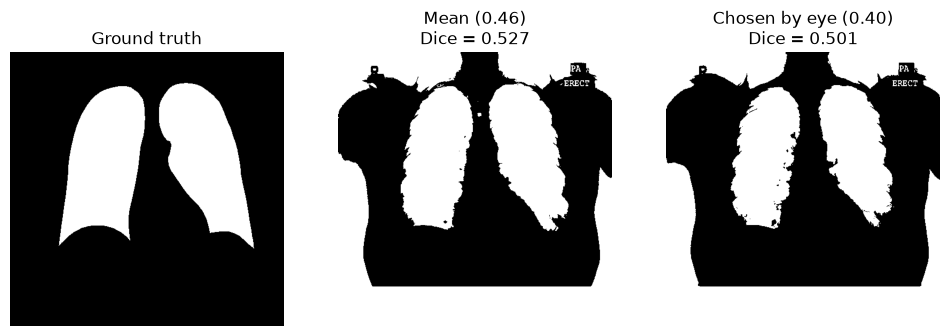

In [32]:
# manual threshold
t_manual = 0.40

# keep pixels below each threshold
mask_mean   = image <= t_mean
mask_manual = image <= t_manual

# plot gt and masks with dice score
fig, axes = plt.subplots(1, 3, figsize=(12, 4))

axes[0].imshow(gt, cmap='gray')
axes[0].set_title('Ground truth')

axes[1].imshow(mask_mean, cmap='gray')
axes[1].set_title(f'Mean ({t_mean:.2f})\nDice = {dice(mask_mean, gt):.3f}')

axes[2].imshow(mask_manual, cmap='gray')
axes[2].set_title(f'Chosen by eye ({t_manual:.2f})\nDice = {dice(mask_manual, gt):.3f}')

for ax in axes:
    ax.axis('off')

plt.savefig('figures/fig_2_threshold_masks.pdf', bbox_inches='tight')
plt.show()

Despite being successful here, the pixel intensity varies across every image, and this threshold would have to differ each time, making this a long task if done manually. 

### Unsupervised thresholding (Otsu's method)

We now try to find the optimal threshold by implementing Otsu's method, which tries every possible threshold and picks the one that makes the two groups as uniform as possible. 

In [35]:
t_otsu    = filters.threshold_otsu(image)
mask_otsu = image <= t_otsu

print(f'Mean threshold   : {t_mean:.2f}, Dice = {dice(mask_mean, gt):.3f}')
print(f'Manual           : {t_manual:.2f}, Dice = {dice(mask_manual, gt):.3f}')
print(f'Otsu threshold   : {t_otsu:.2f}, Dice = {dice(mask_otsu, gt):.3f}')

Mean threshold   : 0.46, Dice = 0.527
Manual           : 0.40, Dice = 0.501
Otsu threshold   : 0.46, Dice = 0.528


Interestingly, Otsu selected the same threshold as the mean in the previous step. 

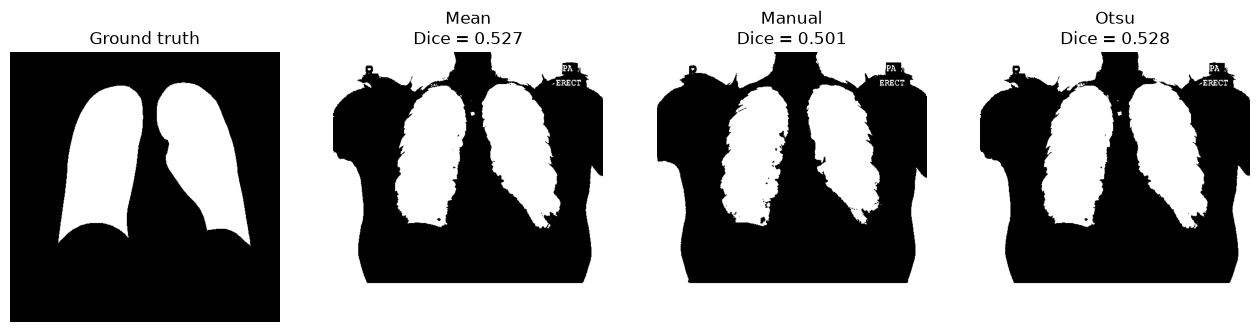

In [36]:
masks  = [gt, mask_mean, mask_manual, mask_otsu]
titles = ['Ground truth', 'Mean', 'Manual', 'Otsu']

fig, axes = plt.subplots(1, 4, figsize=(16, 4))

for ax, m, title in zip(axes, masks, titles):

    # add dice to every mask except ground truth
    if m is not gt:
        title += f'\nDice = {dice(m, gt):.3f}'

    ax.imshow(m, cmap='gray')
    ax.set_title(title)
    ax.axis('off')

plt.savefig('figures/fig_2_otsu_comparison.pdf', bbox_inches='tight')
plt.show()

All three thresholds have found the lungs, but they also select the air outside the body and leave holes, limiting the Dice score. To compare them. further, we can see how the mean and otsu threshold compare against several images. 

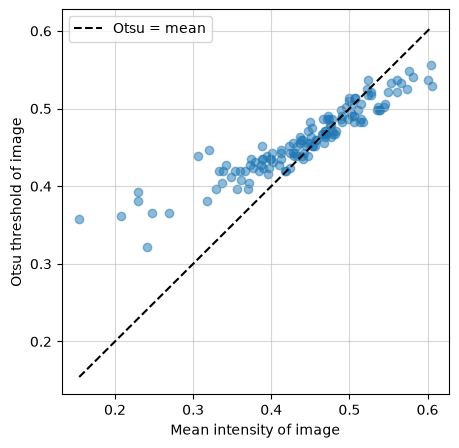

Mean thresholds : 0.15 to 0.61
Otsu thresholds : 0.32 to 0.56


In [40]:
# mean and otsu threshold of every image
image_means = []
image_otsus = []

# find mean and otsu threshold for every image
for name in all_cases:
    img = util.img_as_float(io.imread(IMAGE_DIR / name, as_gray=True))
    image_means.append(img.mean())
    image_otsus.append(filters.threshold_otsu(img))

# set range to include all thresholds
lo = min(image_means + image_otsus)
hi = max(image_means + image_otsus)

# plot thresholds against each other
plt.figure(figsize=(5, 5))

plt.scatter(image_means, image_otsus, alpha=0.5)
plt.plot([lo, hi], [lo, hi], 'k--', label='Otsu = mean')
plt.xlabel('Mean intensity of image')
plt.ylabel('Otsu threshold of image')
plt.legend()
plt.grid(alpha=0.5)

plt.savefig('figures/fig_2_mean_vs_otsu.pdf', bbox_inches='tight')
plt.show()

print(f'Mean thresholds : {min(image_means):.2f} to {max(image_means):.2f}')
print(f'Otsu thresholds : {min(image_otsus):.2f} to {max(image_otsus):.2f}')

Across all 137 images, the mean intensity and Otsu’s threshold are strongly related, with brighter images getting higher thresholds from both methods, so no single fixed threshold suits every image. However, Otsu’s threshold varies much less (about 0.32–0.56) than the mean (about 0.15–0.61).

## PART 3: Further Image Processing

### Filtering and morphological operations

To improve the performance achieved by thresholding, we can now apply the following to our segmentations:

- Gaussian filtering before thresholding to supress pixel noise
- Opening with Erosion then Dilation to remove any small specks
- Clearing the border to remove the background air
- Clustering to keep only the two large lungs
- Filling holes that are inside of the lungs
- Closing with Dilation then Erosion to smooth the outline

Each step is applied one at a time to enable th progression to be visualised.

We first load the same normal case as before:

In [118]:
image, gt = load_case(normal_cases[0])

# dictionary to store the result after each step,
steps = {}

#### Gaussian smoothing

Each pixel is replaced by a weighted average of its neighbours, smoothing out pixel-level noise. 

In [119]:
# blur x-ray to suppress pixel noise
smooth = filters.gaussian(image, sigma=2)

steps['Gaussian smoothed'] = smooth

#### Otsu threshold

We now apply otsu thresholding to the smoothed image.

In [120]:
# otsu threshold on the smoothed image
t = filters.threshold_otsu(smooth)

binary = smooth <= t

steps['Otsu threshold'] = binary

#### Opening

Opening is an erosion followed by a dilation, where:

- erosion shrinks every region by the disk radius, so anything smaller disappears
- dilation grows the remaining regions back to roughly their original size

I chose to use a disk of radius 5 as the lungs are quite a large region. 

In [ ]:
# erosion then dilation with a disk of radius 5 pixels
binary = morphology.opening(binary, morphology.disk(5))

steps['Opening'] = binary

#### Clear border

The air outside the body is dark, so the threshold keeps it, so we use `clear_border` to remove it from the mask. 

In [122]:
# remove every region touching image edge
binary = clear_border(binary)

steps['Clear border'] = binary

#### Keeping the the two largest regions

Opening may not have removed all small blobs, but we know that we are expecting the two lungs to be the largest regions in the threshold, and we can isolate them using:

1. `measure.label` to give every separate region its own number
2. `measure.regionprops` to measure the area of each region

In [123]:
def keep_largest_regions(binary, n=2):
    """
    Keep only the n largest connected regions of a binary mask.
    """

    # give every region its own number
    labels = measure.label(binary)

    # measure every region and sort by area
    regions = sorted(measure.regionprops(labels), key=lambda r: r.area, reverse=True)

    # keep largest n
    keep = [r.label for r in regions[:n]]

    # return true only for pixels belonging to those regions
    return np.isin(labels, keep)

We now apply this to our mask

In [124]:
binary = keep_largest_regions(binary, n=2)

steps['Two largest regions'] = binary

#### Fill holes

There may be holes inside the mask from ribs and other bright elements showing up on the X-ray, but the ground truth includes these in the segmentation, so we fill the holes seen in our masks. 

In [125]:
# fill any region completely enclosed by lung
binary = ndi.binary_fill_holes(binary)

steps['Fill holes'] = binary

#### Closing

Closing is a dilation followed by an erosion, which fills small gaps and notches along the edge, then shrinks the mask back to roughly its original size, providing a smoother outline. 

In [126]:
binary = morphology.closing(binary, morphology.disk(5))

steps['Closing'] = binary

#### Effect of each step

We can now plot the result after every step to see the progression. 

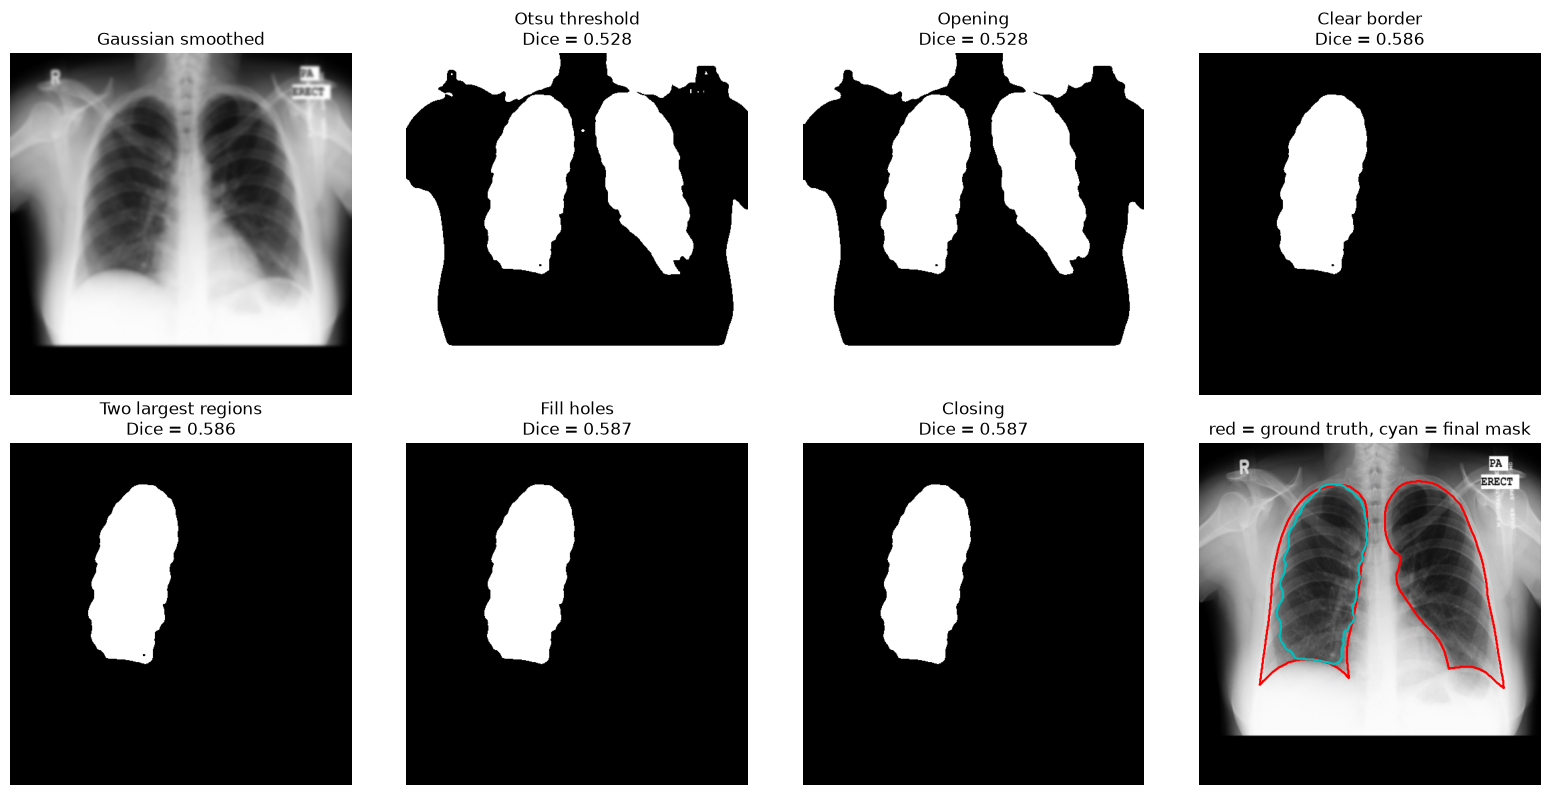

In [127]:
fig, axes = plt.subplots(2, 4, figsize=(16, 8))

for ax, (title, im) in zip(axes.ravel(), steps.items()):

    # set dice to only binary masks
    if im.dtype == bool:
        title += f'\nDice = {dice(im, gt):.3f}'

    ax.imshow(im, cmap='gray')
    ax.set_title(title)

# overlap gt and final mask on one x-ray for comparison
axes[1, 3].imshow(image, cmap='gray')
axes[1, 3].contour(gt, levels=[0.5], colors='r')
axes[1, 3].contour(binary, levels=[0.5], colors='c')
axes[1, 3].set_title('red = ground truth, cyan = final mask')

# hide axes on every panel
for ax in axes.ravel():
    ax.axis('off')

plt.tight_layout()
plt.savefig('figures/fig_3_pipeline_steps.pdf', bbox_inches='tight')
plt.show()

The Dice score only rises from 0.528 to 0.587 because one lung disappears at the clear border step. This is because the top of the right-hand lung is joined to the dark air above the shoulder, so it is treated as one region, and removing the outside air removes the lung with it. Opening with a disk of radius 5 was meant to cut links like this, but it barely changes the mask (Dice 0.528 before and after), so the link must be wider than the disk.

To test this, we repeat the clean-up with larger opening disks:

In [128]:
# try larger opening disks on this image, all other steps unchanged
for r in [5, 10, 15, 20, 25, 30]:

    m = morphology.opening(steps['Otsu threshold'], morphology.disk(r))
    m = clear_border(m)
    m = keep_largest_regions(m, n=2)
    m = ndi.binary_fill_holes(m)
    m = morphology.closing(m, morphology.disk(5))

    print(f'disk({r:2d}) : Dice = {dice(m, gt):.3f}')

disk( 5) : Dice = 0.587
disk(10) : Dice = 0.583
disk(15) : Dice = 0.581
disk(20) : Dice = 0.885
disk(25) : Dice = 0.882
disk(30) : Dice = 0.880


The Dice stays at about 0.58 until a radius of 20, where it jumps to 0.885 because both lungs now survive. The link between the lung and the air above the shoulder is therefore about 40 pixels wide, not a thin strip. Below radius 20, a larger disk slightly lowers the Dice, because it rounds off the edges of the remaining lung.

We combine all steps into a first version of the pipeline, using an opening radius of 20.

In [129]:
def segment_lungs_v1(image, open_radius=20):

    """
    Version 1: gaussian smoothing, otsu threshold, opening, clear border, two largest regions, fill holes, closing.
    """

    # gaussian smoothing
    smooth = filters.gaussian(image, sigma=2)

    # thresholding
    t = filters.threshold_otsu(smooth)
    binary = smooth <= t

    # opening to remove specks
    binary = morphology.opening(binary, morphology.disk(open_radius))

    # remove air outside the body
    binary = clear_border(binary)

    # keep the two lungs
    binary = keep_largest_regions(binary, n=2)

    # fill holes inside the lungs
    binary = ndi.binary_fill_holes(binary)

    # closing to smooth the outline
    binary = morphology.closing(binary, morphology.disk(5))

    return binary

### Testing

A radius of 20 was chosen using a single image, so before using the pipeline on the whole data set we check it on
16 random normal cases.

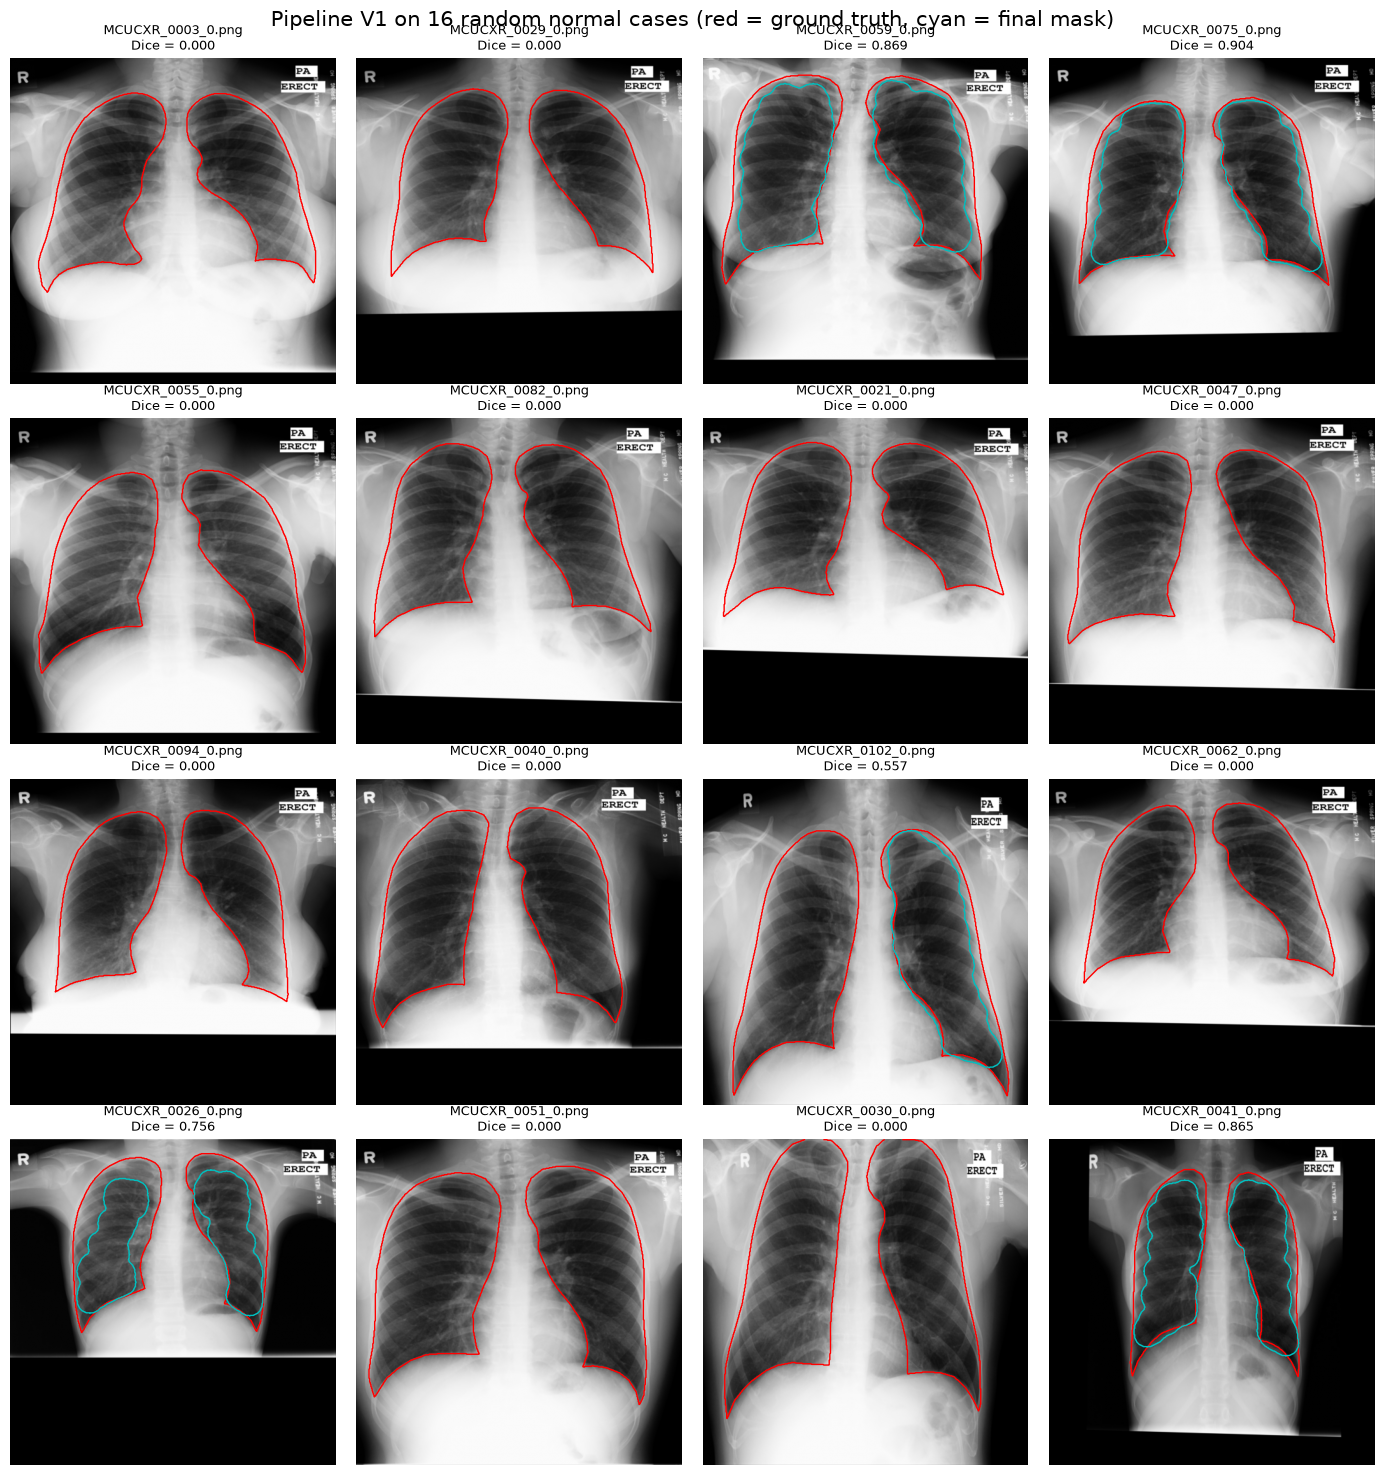

Mean Dice    : 0.247
Lowest Dice  : 0.000
Empty masks  : 11


In [130]:
# select 16 random normal cases
rng       = np.random.default_rng(SEED)
check_set = rng.choice(normal_cases, 16, replace=False)

# load once, reuse in every test below
loaded = [load_case(n) for n in check_set]

fig, axes = plt.subplots(4, 4, figsize=(14, 15))

# keep dice of every case
check_dice = []

for ax, name, (img, gt) in zip(axes.ravel(), check_set, loaded):

    # run version 1 of pipeline
    pred  = segment_lungs_v1(img)
    score = dice(pred, gt)
    check_dice.append(score)

    # plot x-ray with gt in red and final mask in cyan
    ax.imshow(img, cmap='gray')
    ax.contour(gt, levels=[0.5], colors='r', linewidths=1)
    ax.contour(pred, levels=[0.5], colors='c', linewidths=1)
    ax.set_title(f'{name}\nDice = {score:.3f}', fontsize=9)
    ax.axis('off')

plt.suptitle('Pipeline V1 on 16 random normal cases (red = ground truth, cyan = final mask)', fontsize=15)
plt.tight_layout()
plt.savefig('figures/fig_3_v1_check.pdf', bbox_inches='tight')
plt.show()

print(f'Mean Dice    : {np.mean(check_dice):.3f}')
print(f'Lowest Dice  : {np.min(check_dice):.3f}')
print(f'Empty masks  : {sum(s == 0 for s in check_dice)}')

Version 1 fails on most cases, as the mean Dice is 0.247, and 11 of the 16 masks are completely empty, meaning both lungs were removed. Changing the opening radius to other values gives the same pattern, so the problem is not the opening. Since only `clear_border` can remove everything, both lungs must be joined to the image edge in these cases.

The cases that worked (e.g. 0026, 0041, 0059, 0075) all have large black areas at the sides of the image, while most failures have the body filling the whole width. Earlier, we saw that images with more black background get a lower Otsu threshold, so we look at the thresholded masks of some failed cases:

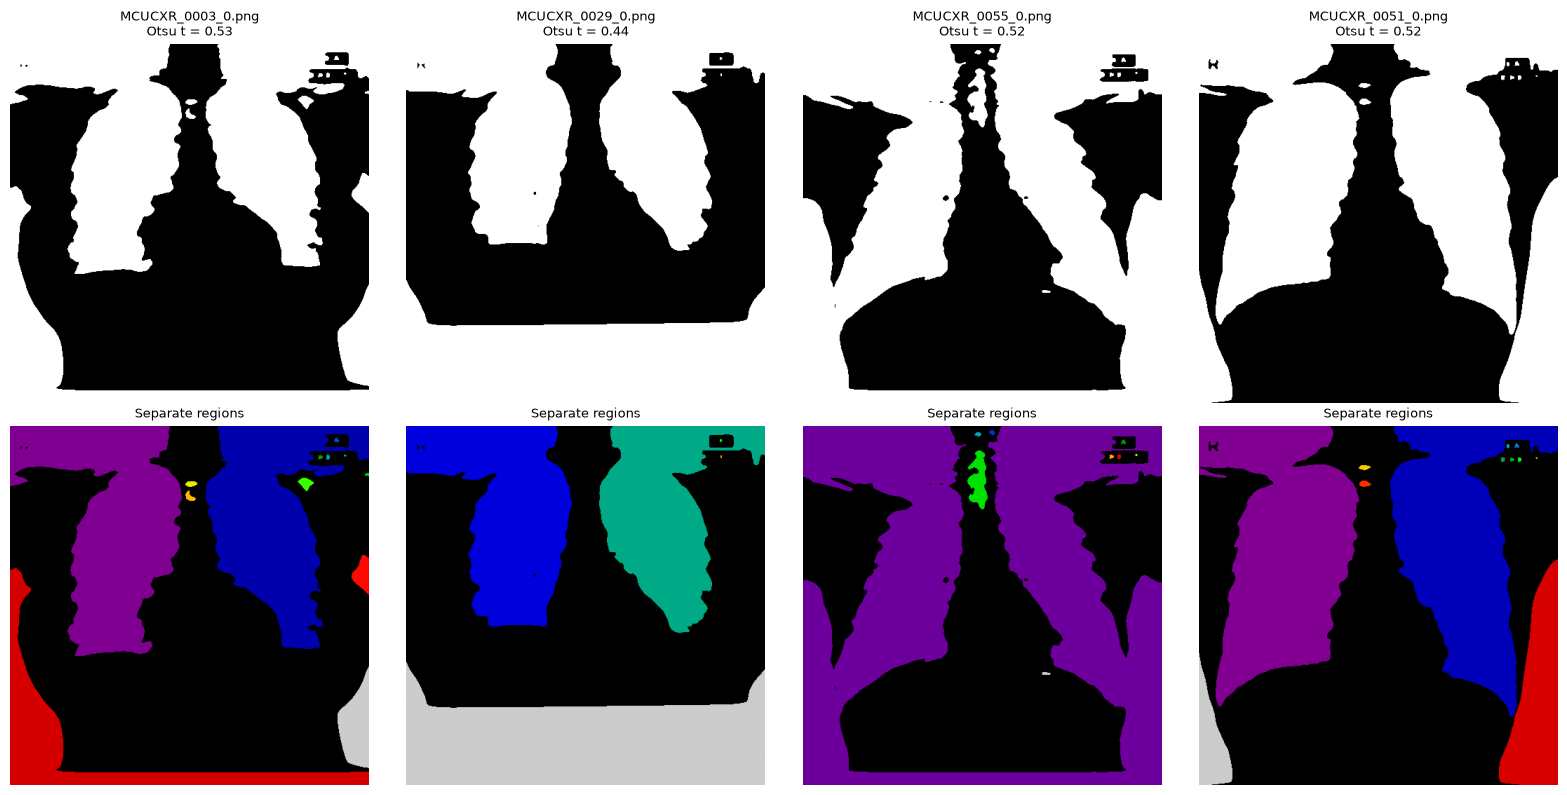

In [131]:
fail_cases = ['MCUCXR_0003_0.png', 'MCUCXR_0029_0.png', 'MCUCXR_0055_0.png', 'MCUCXR_0051_0.png']

fig, axes = plt.subplots(2, 4, figsize=(16, 8))

for col, name in enumerate(fail_cases):

    image, gt = load_case(name)

    # otsu mask before any clean-up
    smooth = filters.gaussian(image, sigma=2)
    t      = filters.threshold_otsu(smooth)
    binary = smooth <= t

    # top row: the thresholded mask
    axes[0, col].imshow(binary, cmap='gray')
    axes[0, col].set_title(f'{name}\nOtsu t = {t:.2f}', fontsize=9)

    # bottom row: separate regions, joined regions share a colour
    axes[1, col].imshow(measure.label(binary), cmap='nipy_spectral')
    axes[1, col].set_title('Separate regions', fontsize=9)

for ax in axes.ravel():
    ax.axis('off')

plt.tight_layout()
plt.show()

We can clearly see that in all of these, the lungs share a colour with the background, so are removed during clearing. 

#### Diagnosis 1: the threshold

It is possible that the black background and the soft tissue at the edges of the scans is distorting the otsu threshold, so choosing a threshold using only the central part of the image might mitiage this. 

In [132]:
def segment_lungs_v2(image, open_radius=20, crop=0.2):

    """
    Version 2: as version 1, but the otsu threshold is chosen from the centre of the image only.
    """

    # gaussian smoothing
    smooth = filters.gaussian(image, sigma=2)

    # central part of the image
    h, w   = smooth.shape
    centre = smooth[int(crop * h):int((1 - crop) * h), int(crop * w):int((1 - crop) * w)]

    # otsu threshold chosen from the centre only, then applied to the whole image
    t      = filters.threshold_otsu(centre)
    binary = smooth <= t

    # opening removes specks and cuts the link between the lungs and the outside air
    binary = morphology.opening(binary, morphology.disk(open_radius))

    # remove air outside the body
    binary = clear_border(binary)

    # keep the two lungs
    binary = keep_largest_regions(binary, n=2)

    # fill holes inside the lungs
    binary = ndi.binary_fill_holes(binary)

    # closing to smooth the outline
    binary = morphology.closing(binary, morphology.disk(5))

    return binary

We can now test if this worked on the same subset as before. 

In [133]:
for crop in [0, 0.15, 0.2, 0.25]:
    for r in [15, 20, 25]:

        scores = [dice(segment_lungs_v2(img, open_radius=r, crop=crop), gt) for img, gt in loaded]

        print(f'crop = {crop:.2f}, disk({r:2d}) : mean Dice = {np.mean(scores):.3f}, '
              f'lowest = {np.min(scores):.3f}, empty masks = {sum(s == 0 for s in scores)}')

crop = 0.00, disk(15) : mean Dice = 0.232, lowest = 0.000, empty masks = 11
crop = 0.00, disk(20) : mean Dice = 0.247, lowest = 0.000, empty masks = 11
crop = 0.00, disk(25) : mean Dice = 0.281, lowest = 0.000, empty masks = 10
crop = 0.15, disk(15) : mean Dice = 0.070, lowest = 0.000, empty masks = 14
crop = 0.15, disk(20) : mean Dice = 0.109, lowest = 0.000, empty masks = 13
crop = 0.15, disk(25) : mean Dice = 0.129, lowest = 0.000, empty masks = 13
crop = 0.20, disk(15) : mean Dice = 0.035, lowest = 0.000, empty masks = 15
crop = 0.20, disk(20) : mean Dice = 0.074, lowest = 0.000, empty masks = 14
crop = 0.20, disk(25) : mean Dice = 0.110, lowest = 0.000, empty masks = 13
crop = 0.25, disk(15) : mean Dice = 0.035, lowest = 0.000, empty masks = 15
crop = 0.25, disk(20) : mean Dice = 0.074, lowest = 0.000, empty masks = 14
crop = 0.25, disk(25) : mean Dice = 0.074, lowest = 0.000, empty masks = 14


We see that cropping makes the results worse, as the empty masks rise from 11 to as many as 15. This is because removing the edges removes most of the black background, pushing the Otsu threshold up, meaning that it was already too high.

The reason is that Otsu splits the image into two groups, but a chest X-ray has three main groups, corresponding to the dark lungs, medium soft tissue and bright bone, heart and abdomen.

Three-class Otsu (`threshold_multiotsu`) splits the image into three groups instead, and its lower threshold is able to separate the lungs from the soft tissue. To test this, we compare the thresholds for the 16 cases with the best possible threshold for each image, found using the ground truth:

In [134]:
rows = []

for name, (img, gt) in zip(check_set, loaded):

    smooth = filters.gaussian(img, sigma=2)

    # best threshold using the ground truth, for diagnosis only
    ts     = np.linspace(0.05, 0.95, 91)
    t_best = ts[np.argmax([dice(smooth < t, gt) for t in ts])]

    # current two-class otsu threshold
    t_otsu = filters.threshold_otsu(smooth)

    # three-class otsu on body pixels only, lower threshold
    t_multi = threshold_multiotsu(smooth[smooth > 0.05], classes=3)[0]

    rows.append({'file': name, 'best': t_best, 'otsu': t_otsu, 'multi-otsu': t_multi})

pd.DataFrame(rows).round(2)

,file,best,otsu,multi-otsu
0,MCUCXR_0003_0.png,0.54,0.53,0.44
1,MCUCXR_0029_0.png,0.52,0.44,0.42
2,MCUCXR_0059_0.png,0.53,0.48,0.40
3,MCUCXR_0075_0.png,0.51,0.45,0.40
4,MCUCXR_0055_0.png,0.51,0.52,0.41
5,MCUCXR_0082_0.png,0.49,0.46,0.43
6,MCUCXR_0021_0.png,0.57,0.45,0.45
7,MCUCXR_0047_0.png,0.53,0.45,0.41
8,MCUCXR_0094_0.png,0.52,0.44,0.39
9,MCUCXR_0040_0.png,0.47,0.41,0.38


We can see that the Two-class Otsu is close to the best threshold for msot cases, whereas the multi-class otsu sits below it. 

Version 3 uses the lower three-class Otsu threshold.

In [135]:
def segment_lungs_v3(image, open_radius=5):

    """
    Version 3: as version 1, but with the lower threshold from three-class otsu.
    """

    # gaussian smoothing
    smooth = filters.gaussian(image, sigma=2)

    # three-class otsu (lungs / soft tissue / bone) on body pixels only, keep the lower threshold
    t      = threshold_multiotsu(smooth[smooth > 0.05], classes=3)[0]
    binary = smooth <= t

    # opening removes specks and cuts the link between the lungs and the outside air
    binary = morphology.opening(binary, morphology.disk(open_radius))

    # remove air outside the body
    binary = clear_border(binary)

    # keep the two lungs
    binary = keep_largest_regions(binary, n=2)

    # fill holes inside the lungs
    binary = ndi.binary_fill_holes(binary)

    # closing to smooth the outline
    binary = morphology.closing(binary, morphology.disk(5))

    return binary

We now test this as before:

In [136]:
for r in [5, 10, 20, 25]:

    scores = [dice(segment_lungs_v3(img, open_radius=r), gt) for img, gt in loaded]

    print(f'disk({r:2d}) : mean Dice = {np.mean(scores):.3f}, '
          f'lowest = {np.min(scores):.3f}, empty masks = {sum(s == 0 for s in scores)}')

disk( 5) : mean Dice = 0.485, lowest = 0.000, empty masks = 4
disk(10) : mean Dice = 0.496, lowest = 0.000, empty masks = 4
disk(20) : mean Dice = 0.492, lowest = 0.000, empty masks = 5
disk(25) : mean Dice = 0.481, lowest = 0.000, empty masks = 5


Three-class Otsu shows a large improvement, as the empty masks drop from 11 to 4 and the mean Dice rises from 0.247 to about 0.49. However, about half the cases are still losing one or both lungs, and the opening radius still makes almost no difference. 

To see why, we plot the regions just before `clear_border`, with each separate region in its own colour:

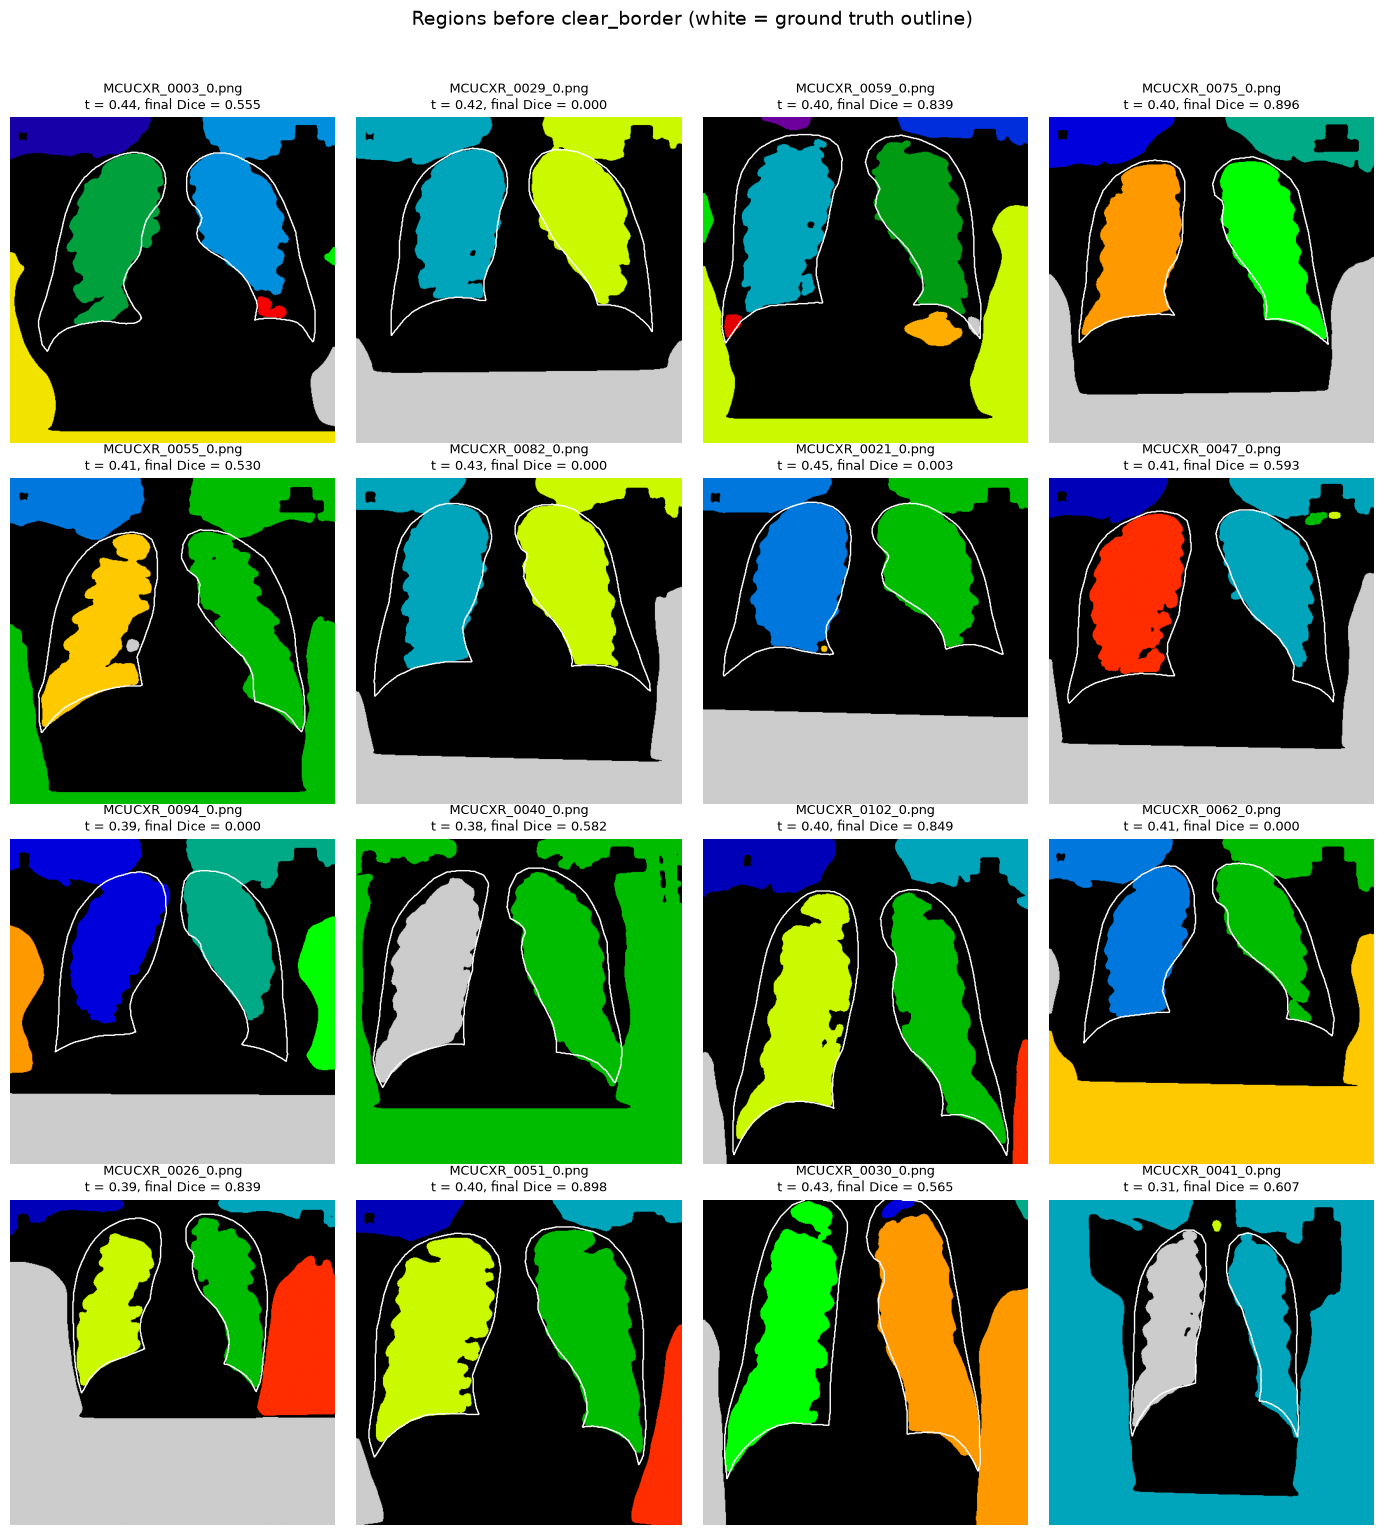

In [138]:
fig, axes = plt.subplots(4, 4, figsize=(14, 15))

for ax, name, (img, gt) in zip(axes.ravel(), check_set, loaded):

    # same steps as version 3, stopping just before clear_border
    smooth = filters.gaussian(img, sigma=2)
    t      = threshold_multiotsu(smooth[smooth > 0.05], classes=3)[0]
    binary = morphology.opening(smooth < t, morphology.disk(5))

    # every separate region gets its own colour, joined regions share a colour
    ax.imshow(measure.label(binary), cmap='nipy_spectral')

    # ground truth outline in white
    ax.contour(gt, levels=[0.5], colors='w', linewidths=1)

    score = dice(segment_lungs_v3(img), gt)
    ax.set_title(f'{name}\nt = {t:.2f}, final Dice = {score:.3f}', fontsize=9)
    ax.axis('off')

plt.suptitle('Regions before clear_border (white = ground truth outline)', fontsize=14, y=1.02)
plt.tight_layout()
plt.savefig('figures/fig_3_regions_v3.pdf', bbox_inches='tight')
plt.show()

#### Diagnosis 2: links to the image edge

The lungs are now clearly picked out inside the ground-truth outlines, so the threshold is about right. However, in every failed case a lung has the same colour as a region at the image edge, meaning they are one connected
region, so `clear_border` removes them.

A bigger opening does not fix this because opening is erosion then dilation, with erosion breaking the link, but dilation grows the regions back.

The fix is to decide which regions to keep while they are still separated by:

1. Eroding the mask to break the links
2. Clearing the border and keeping the two largest regions, which are now the lungs on their own
3. Dilating the two lungs back, but only inside the original thresholded mask, so they recover their shape
   without regrowing into the removed regions.

In [145]:
def segment_lungs_v4(image, erode_radius=25):

    """
    Version 4: gaussian smoothing, three-class otsu threshold, then choosing the lungs on an eroded mask
    and growing them back inside the thresholded mask.
    """

    # gaussian smoothing
    smooth = filters.gaussian(image, sigma=2)

    # three-class otsu (lungs / soft tissue / bone) on body pixels only, keep the lower threshold
    t      = threshold_multiotsu(smooth[smooth > 0.05], classes=3)[0]
    binary = smooth < t

    # erode to break the links between the lungs and the dark regions at the image edge
    core = morphology.erosion(binary, morphology.disk(erode_radius))

    # while separated, remove regions touching the edge and keep the two largest
    core = clear_border(core)
    core = keep_largest_regions(core, n=2)

    # grow the two lungs back, only inside the original thresholded mask
    lungs = binary & morphology.dilation(core, morphology.disk(erode_radius))

    # fill holes inside the lungs
    lungs = ndi.binary_fill_holes(lungs)

    # closing to smooth the outline
    lungs = morphology.closing(lungs, morphology.disk(5))

    return lungs

The erosion radius sets a trade-off, as a larger erosion breaks wider links, but too large an erosion removes narrow lungs entirely before they can be grown back. We test a range of radii on the same 16 cases:

In [146]:
for r in [5, 10, 15, 20, 25, 30, 35, 40, 45]:

    scores = [dice(segment_lungs_v4(img, erode_radius=r), gt) for img, gt in loaded]

    print(f'erode radius {r:2d} : mean Dice = {np.mean(scores):.3f}, '
          f'lowest = {np.min(scores):.3f}, empty masks = {sum(s == 0 for s in scores)}')

erode radius  5 : mean Dice = 0.486, lowest = 0.000, empty masks = 3
erode radius 10 : mean Dice = 0.602, lowest = 0.000, empty masks = 3
erode radius 15 : mean Dice = 0.630, lowest = 0.000, empty masks = 2
erode radius 20 : mean Dice = 0.687, lowest = 0.000, empty masks = 1
erode radius 25 : mean Dice = 0.746, lowest = 0.529, empty masks = 0
erode radius 30 : mean Dice = 0.760, lowest = 0.526, empty masks = 0
erode radius 35 : mean Dice = 0.719, lowest = 0.312, empty masks = 0
erode radius 40 : mean Dice = 0.688, lowest = 0.184, empty masks = 0
erode radius 45 : mean Dice = 0.596, lowest = 0.000, empty masks = 3


The mean Dice rises from 0.486 at radius 5 to 0.746 at radius 25, with no empty masks, as wider links are broken.
Beyond a radius of 30 the erosion starts deleting narrow lungs as the lowest Dice drops to 0.31 at 35, and three masks are empty at 45. Radii 25 and 30 perform almost identically (mean 0.746 vs 0.760, lowest 0.53 for both), so we use 25, as the smaller erosion is less likely to remove narrow lungs in cases it was not tuned on, such as the TB cases.

Even at this radius the lowest Dice is about 0.53, so at least one case still loses a lung through a link too wide to break without removing narrower lungs. This is a limitation of using one global threshold with fixed-size morphology.

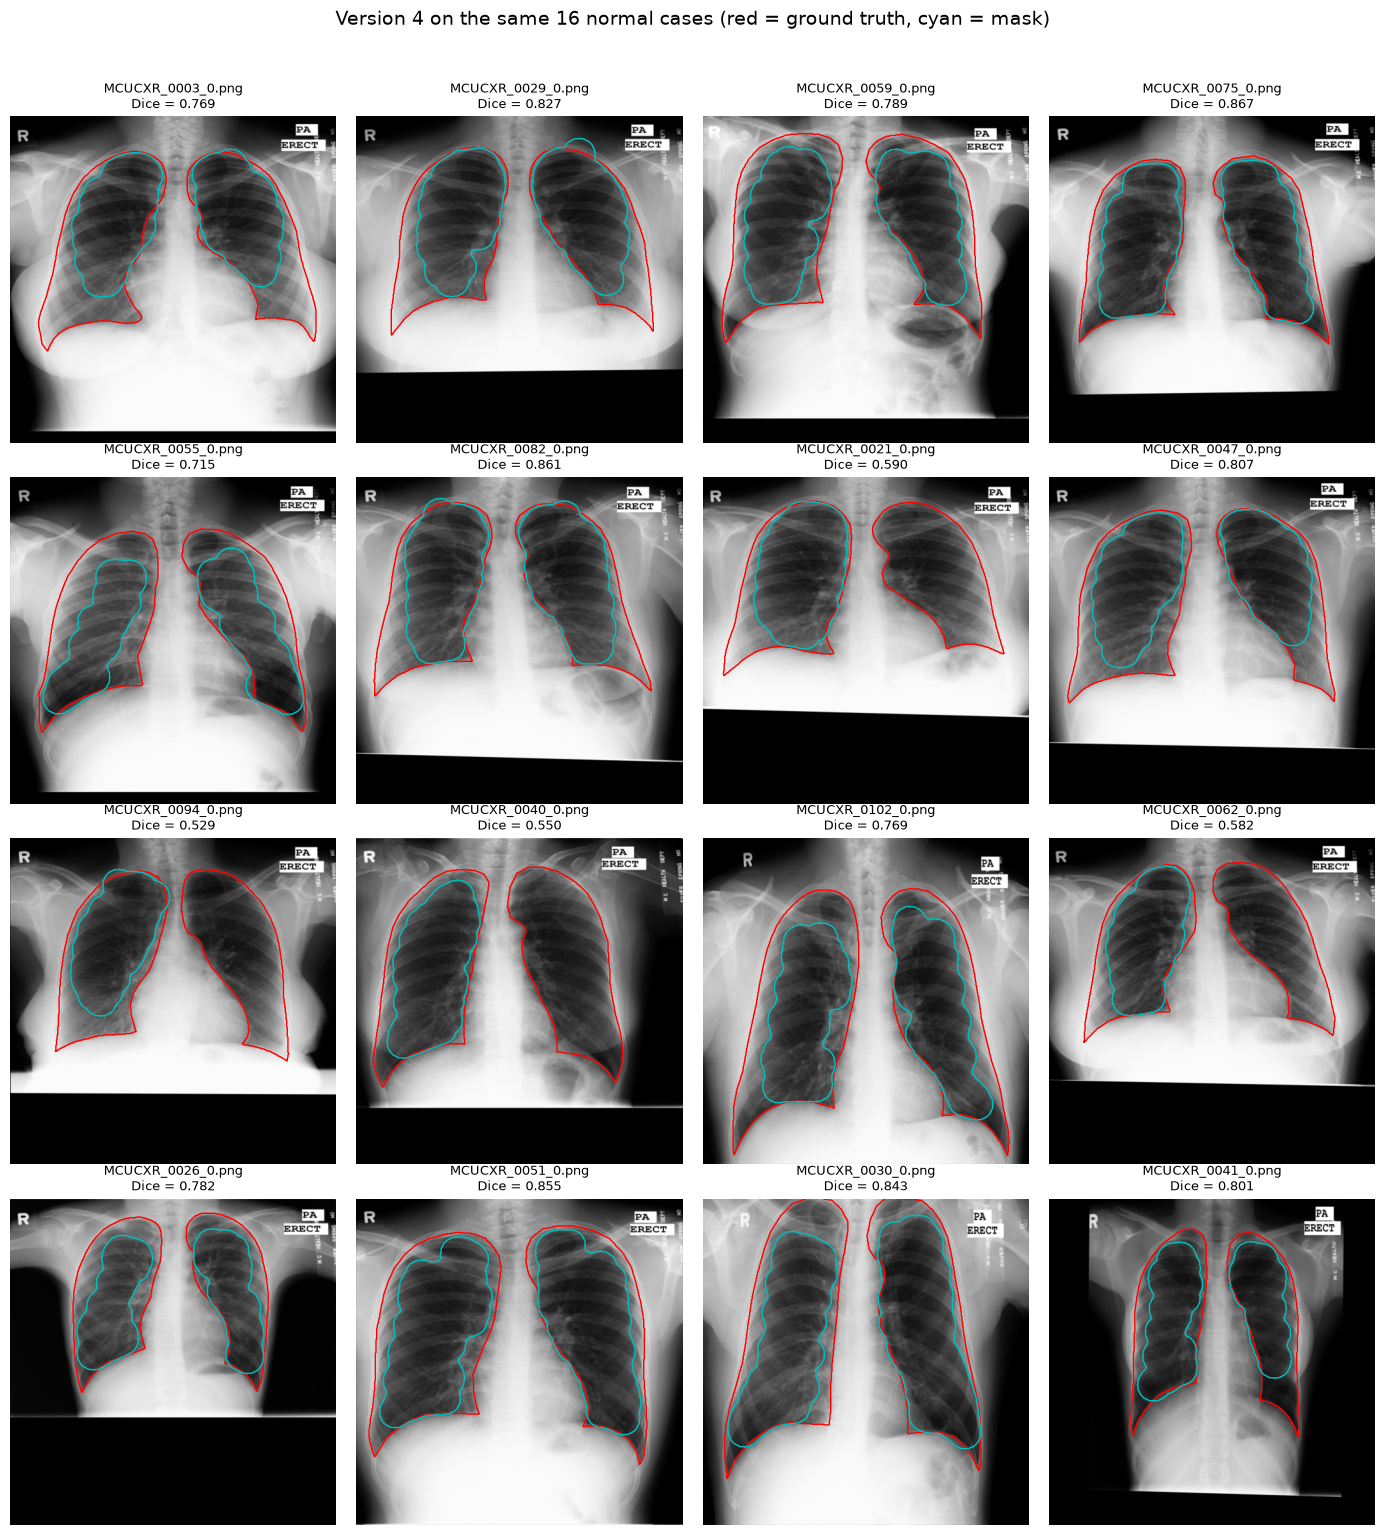

Mean Dice    : 0.746
Lowest Dice  : 0.529
Empty masks  : 0


In [147]:
fig, axes = plt.subplots(4, 4, figsize=(14, 15))

# keep dice of every case
v4_dice = []

for ax, name, (img, gt) in zip(axes.ravel(), check_set, loaded):

    # run version 4
    pred  = segment_lungs_v4(img)
    score = dice(pred, gt)
    v4_dice.append(score)

    # plot x-ray with gt in red and mask in cyan
    ax.imshow(img, cmap='gray')
    ax.contour(gt, levels=[0.5], colors='r', linewidths=1)
    ax.contour(pred, levels=[0.5], colors='c', linewidths=1)
    ax.set_title(f'{name}\nDice = {score:.3f}', fontsize=9)
    ax.axis('off')

plt.suptitle('Version 4 on the same 16 normal cases (red = ground truth, cyan = mask)', fontsize=14, y=1.02)
plt.tight_layout()
plt.savefig('figures/fig_3_v4_check.pdf', bbox_inches='tight')
plt.show()

print(f'Mean Dice    : {np.mean(v4_dice):.3f}')
print(f'Lowest Dice  : {np.min(v4_dice):.3f}')
print(f'Empty masks  : {sum(s == 0 for s in v4_dice)}')

Every case keeps at least one lung and 12 of the 16 keep both (mean Dice 0.746, up from 0.247 for version 1). The four lowest cases (0021, 0040, 0062, 0094, with Dice 0.53–0.59) all lose the right-hand lung in the image (the patient’s left), suggesting that its top remains joined to the dark region at the top-right corner even after erosion.

#### Local thresholding

A global threshold uses one value for the whole image, but the brightness of the lungs is uneven. A local threshold (`threshold_local`) compares each pixel with a Gaussian-weighted mean of itsown `block_size` × `block_size` neighbourhood, so a pixel counts as lung if it is darker than its surroundings. The rest
of the pipeline (erosion-based selection, filling holes, closing) is unchanged.

In [150]:
def segment_lungs(image, block_size=301, erode_radius=15):

    """
    Final version: gaussian smoothing, local threshold, then choosing the lungs on an eroded mask
    and growing them back inside the thresholded mask.
    """

    # gaussian smoothing
    smooth = filters.gaussian(image, sigma=2)

    # local threshold, each pixel compared with a weighted mean of its neighbourhood
    t      = filters.threshold_local(smooth, block_size=block_size)
    binary = smooth <= t

    # erode to break the links between the lungs and the dark regions at the image edge
    core = morphology.erosion(binary, morphology.disk(erode_radius))

    # while separated, remove regions touching the edge and keep the two largest
    core = clear_border(core)
    core = keep_largest_regions(core, n=2)

    # grow the two lungs back, only inside the original thresholded mask
    lungs = binary & morphology.dilation(core, morphology.disk(erode_radius))

    # fill holes inside the lungs
    lungs = ndi.binary_fill_holes(lungs)

    # closing to smooth the outline
    lungs = morphology.closing(lungs, morphology.disk(5))

    return lungs

The neighbourhood size (`block_size`, which must be odd) and the erosion radius both need choosing, so we test
combinations on the same 16 cases:

In [149]:
for b in [101, 151, 201, 251, 301, 351, 401]:
    for r in [15, 20, 25]:

        scores = [dice(segment_lungs(img, block_size=b, erode_radius=r), gt) for img, gt in loaded]

        print(f'block {b:3d}, erode {r:2d} : mean Dice = {np.mean(scores):.3f}, '
              f'lowest = {np.min(scores):.3f}, empty masks = {sum(s == 0 for s in scores)}')

block 101, erode 15 : mean Dice = 0.228, lowest = 0.092, empty masks = 0
block 101, erode 20 : mean Dice = 0.156, lowest = 0.075, empty masks = 0
block 101, erode 25 : mean Dice = 0.066, lowest = 0.000, empty masks = 9
block 151, erode 15 : mean Dice = 0.704, lowest = 0.280, empty masks = 0
block 151, erode 20 : mean Dice = 0.599, lowest = 0.244, empty masks = 0
block 151, erode 25 : mean Dice = 0.514, lowest = 0.228, empty masks = 0
block 201, erode 15 : mean Dice = 0.842, lowest = 0.771, empty masks = 0
block 201, erode 20 : mean Dice = 0.810, lowest = 0.657, empty masks = 0
block 201, erode 25 : mean Dice = 0.763, lowest = 0.576, empty masks = 0
block 251, erode 15 : mean Dice = 0.858, lowest = 0.787, empty masks = 0
block 251, erode 20 : mean Dice = 0.845, lowest = 0.770, empty masks = 0
block 251, erode 25 : mean Dice = 0.822, lowest = 0.704, empty masks = 0
block 301, erode 15 : mean Dice = 0.864, lowest = 0.818, empty masks = 0
block 301, erode 20 : mean Dice = 0.856, lowest = 0

The results show two clear patterns:

- **Block size:** with small blocks the threshold follows local detail such as the ribs, so the lungs break up. With a
  block of 101 pixels the mean Dice is at most 0.23, and with an erosion radius of 25 nine masks are empty. As the block
  grows, each neighbourhood covers both lung and the brighter surrounding tissue, so the threshold sits between them
  while adapting to brighter and darker areas of the image. The mean Dice rises steadily to its best at 301–351 pixels
  (0.864–0.868 with erosion 15, lowest 0.818–0.826).
- **Erosion radius:** for every block size up to 351, a smaller erosion is better (e.g. at 301: 0.864, 0.856 and 0.840
  for radii 15, 20 and 25), because the local threshold already separates the lungs from most of the dark regions at
  the image edge, so a large erosion only removes lung shape. At 401 this reverses: the threshold starts to behave like
  a single global value again, a radius of 15 or 20 is no longer enough to break the links (lowest Dice about 0.55 as a
  lung is lost), and a radius of 25 is needed, as in version 4.

We use a **block size of 301 and an erosion radius of 15**. It performs almost the same as 351 (mean 0.864 vs 0.868)
but is further from the drop at 401, which matters for the TB cases it was not tuned on. The local threshold also allows
a smaller erosion than version 4 (15 vs 25), so the lungs keep more of their shape.

#### Final pipeline on the same cases

We now run the final pipeline on the same 16 normal cases, to compare it with version 4.

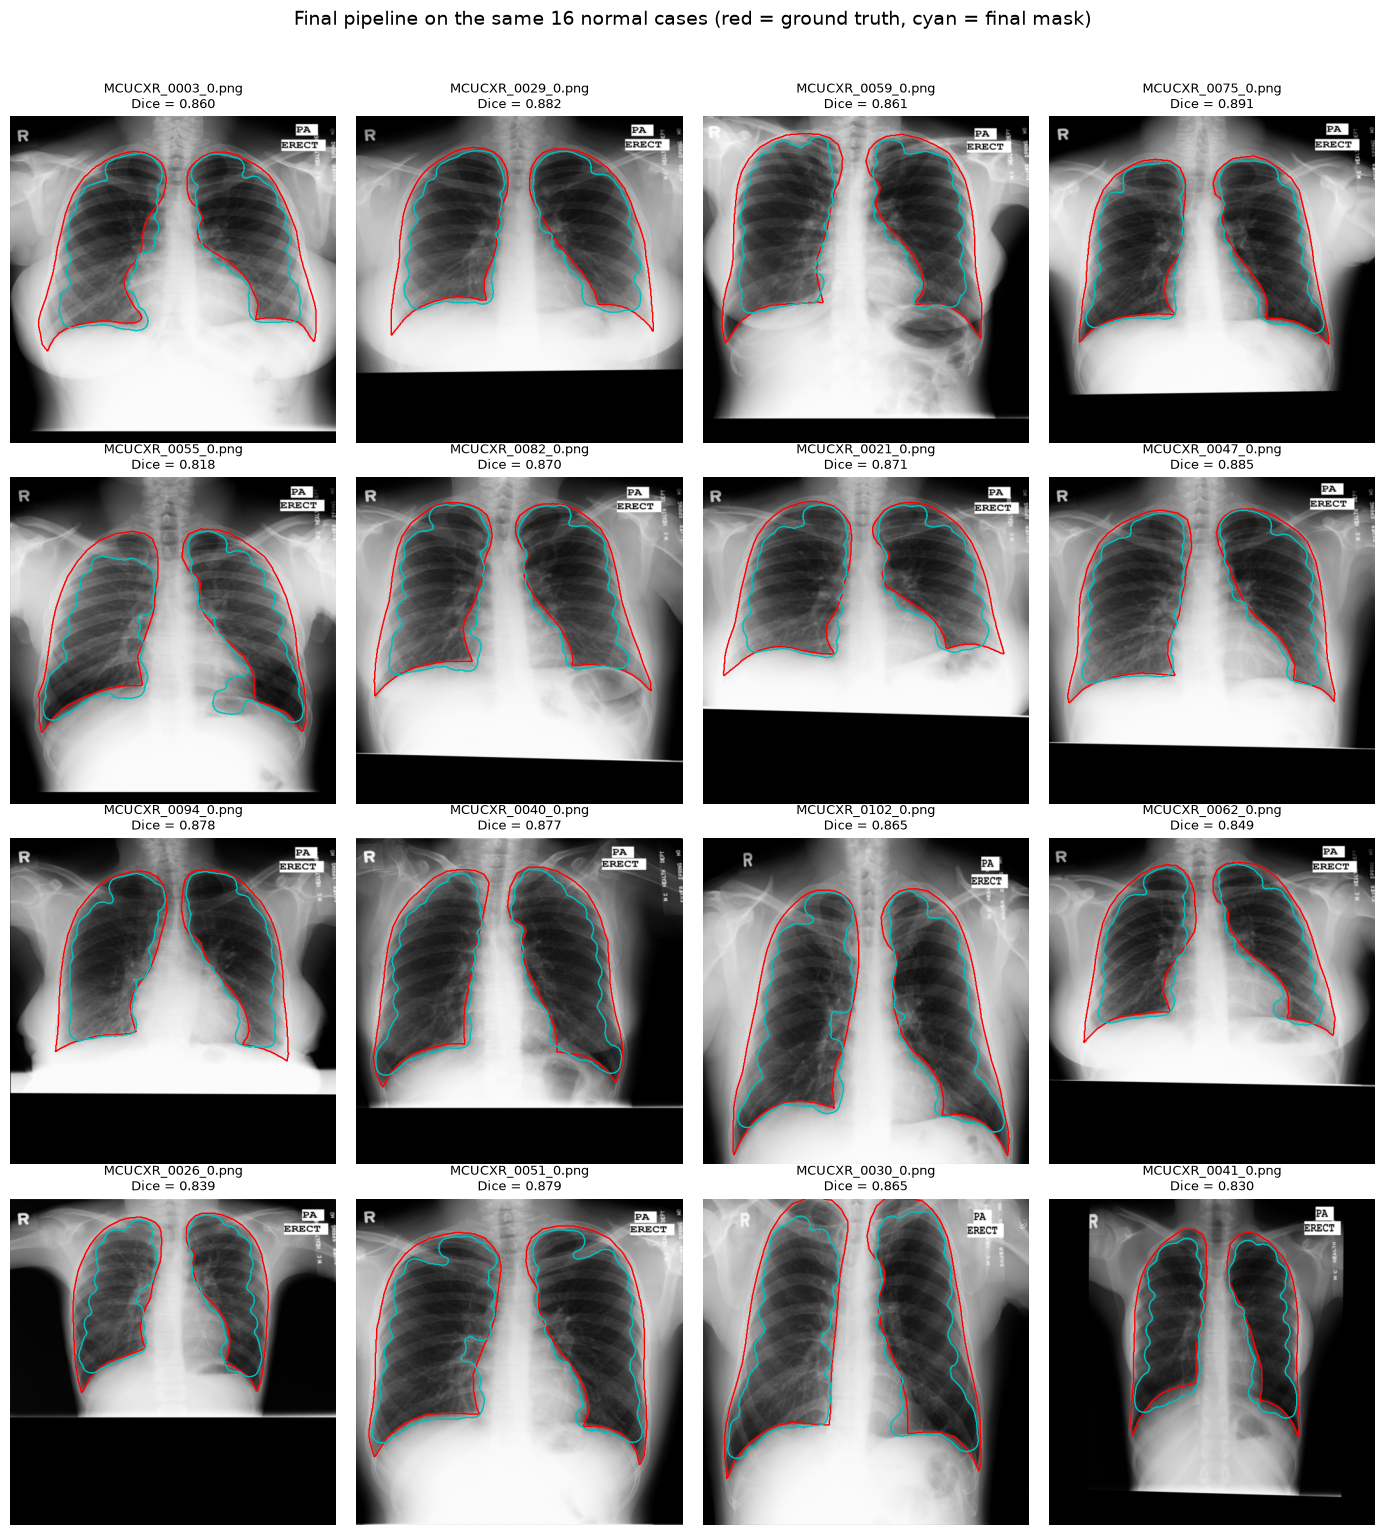

Mean Dice    : 0.864
Lowest Dice  : 0.818
Empty masks  : 0


In [151]:
fig, axes = plt.subplots(4, 4, figsize=(14, 15))

# keep dice of every case
final_dice = []

for ax, name, (img, gt) in zip(axes.ravel(), check_set, loaded):

    # run the final pipeline (local threshold, block 301, erosion 15)
    pred  = segment_lungs(img)
    score = dice(pred, gt)
    final_dice.append(score)

    # plot x-ray with gt in red and final mask in cyan
    ax.imshow(img, cmap='gray')
    ax.contour(gt, levels=[0.5], colors='r', linewidths=1)
    ax.contour(pred, levels=[0.5], colors='c', linewidths=1)
    ax.set_title(f'{name}\nDice = {score:.3f}', fontsize=9)
    ax.axis('off')

plt.suptitle('Final pipeline on the same 16 normal cases (red = ground truth, cyan = final mask)', fontsize=14, y=1.02)
plt.tight_layout()
plt.savefig('figures/fig_3_final_check.pdf', bbox_inches='tight')
plt.show()

print(f'Mean Dice    : {np.mean(final_dice):.3f}')
print(f'Lowest Dice  : {np.min(final_dice):.3f}')
print(f'Empty masks  : {sum(s == 0 for s in final_dice)}')

Comparing this directly against v4 gives:

In [152]:
# dice of version 4 and the final pipeline for each case
compare = pd.DataFrame({'file': check_set, 'version 4': v4_dice, 'final': final_dice})
compare['change'] = compare['final'] - compare['version 4']

compare.round(3)

,file,version 4,final,change
0,MCUCXR_0003_0.png,0.769,0.860,0.091
1,MCUCXR_0029_0.png,0.827,0.882,0.055
2,MCUCXR_0059_0.png,0.789,0.861,0.072
3,MCUCXR_0075_0.png,0.867,0.891,0.025
4,MCUCXR_0055_0.png,0.715,0.818,0.104
5,MCUCXR_0082_0.png,0.861,0.870,0.010
6,MCUCXR_0021_0.png,0.590,0.871,0.281
7,MCUCXR_0047_0.png,0.807,0.885,0.078
8,MCUCXR_0094_0.png,0.529,0.878,0.349
9,MCUCXR_0040_0.png,0.550,0.877,0.327


With the final pipeline, all 16 cases keep both lungs (mean Dice 0.864, lowest 0.818, range 0.818–0.891), and every case
improves on version 4 (by 0.010 to 0.349). The biggest gains are in the four cases that lost a lung with version 4: 0021,
0040, 0062 and 0094 rise from 0.53–0.59 to 0.85–0.88, as the local threshold separates the right-hand lung from the
dark region at the top-right corner. The smaller erosion also lets the masks follow the lung edges more closely,
especially along the outer edges and the lung tops.

The remaining differences from the ground truth are mostly **under-segmentation** in the same places as before:

- the **lower outer corners** (costophrenic angles) are still missed, e.g. 0021, 0003 and 0029, where the lung is
  overlapped by the diaphragm and is brighter than its surroundings;
- the outlines are still **wavy along the ribs**, e.g. 0026, 0040 and 0041, because ribs crossing the lung edge are
  brighter than the local threshold;
- a few cases have **notches** where bright structures border the lung, such as the heart edge at the base of
  the right-hand lung in 0055 and the collarbone at the top of the lung in 0051.

| Version | Change | Mean Dice (16 cases) | Empty masks |
|---|---|---|---|
| 1 | Otsu + opening (radius 20) | 0.247 | 11 |
| 2 | Otsu from image centre | 0.074 | 14 |
| 3 | Three-class Otsu + opening (radius 10) | 0.496 | 4 |
| 4 | Three-class Otsu + erosion-based selection (radius 25) | 0.746 | 0 |
| Final | Local threshold (block 301) + erosion-based selection (radius 15) | 0.864 | 0 |

The threshold method, block size and erosion radius were all chosen using these 16 normal cases, so these scores are
likely to be optimistic. Step (8) tests the final pipeline on all 137 cases, including the 57 TB cases that were not
used for tuning.

## PART 4: Assessment of Segmentation

### Normal vs abnormal cases

The final pipeline was developed and tuned on 16 normal cases, so we now run it on all 137 cases (80 normal, 57 TB) to
see how well it works on cases it was not tuned on, and whether it works as well for TB cases as for normal ones.

To show what each part of the work contributes, we compare five versions on the same images:

| Version | What it is |
|---|---|
| mean only | threshold at the mean intensity (naive, step 4) |
| fixed only | threshold at the value chosen by eye from one histogram (supervised, step 4) |
| otsu only | two-class Otsu threshold (step 5) |
| local only | the local threshold used in the final pipeline, without any clean-up |
| final pipeline | local threshold + erosion-based selection, fill holes and closing (step 6) |

The four threshold-only versions are applied to the same Gaussian-smoothed image as the final pipeline, so the difference
between **local only** and **final pipeline** is exactly what the morphological clean-up adds.

`N_PER_CLASS` allows a small subset to be used while testing (`None` uses every image). Loading the full-size images is
the slow part, so all 137 cases take a few minutes.

In [ ]:
# e.g. 10 for a quick test, None for all images
N_PER_CLASS = None

cases = normal_cases[:N_PER_CLASS] + tb_cases[:N_PER_CLASS]

# column names of the versions being compared
methods = ['mean only', 'fixed only', 'otsu only', 'local only', 'final pipeline']

# one dictionary per image, turned into a table at the end
rows = []

for name in cases:

    image, gt = load_case(name)
    row = {'file': name, 'class': 'TB' if get_label(name) else 'normal'}

    # same smoothing as the final pipeline
    smooth = filters.gaussian(image, sigma=2)

    # threshold only, lungs are dark so keep pixels below each threshold
    row['mean only']  = dice(smooth < smooth.mean(), gt)
    row['fixed only'] = dice(smooth < t_manual, gt)
    row['otsu only']  = dice(smooth < filters.threshold_otsu(smooth), gt)
    row['local only'] = dice(smooth < filters.threshold_local(smooth, block_size=301), gt)

    # full final pipeline
    row['final pipeline'] = dice(segment_lungs(image), gt)

    rows.append(row)

# turn into a table and save
results = pd.DataFrame(rows)
results.to_csv('results/segmentation_scores.csv', index=False)

results.head()

#### Summary per class

Mean, standard deviation and median Dice of each version, separately for normal and TB cases:

In [ ]:
# mean, std and median of every version, per class
summary = results.groupby('class')[methods].agg(['mean', 'std', 'median'])

summary.round(3).T

[Describe the table, e.g.: "All threshold-only versions score poorly (mean Dice 0.XX–0.XX), because they also include
the air outside the body and leave holes. The local threshold alone scores 0.XX, and the clean-up raises this to 0.XX for
normal cases, showing that most of the improvement comes from the morphological steps. The final pipeline scores 0.XX on
all 80 normal cases, close to the 0.864 on the 16 tuning cases, so it generalises well to normal cases it was not tuned on.
On TB cases it scores 0.XX."]

The box plot below shows the full distribution of Dice for each version, with normal and TB cases side by side.
Each box shows the middle 50% of cases, the line is the median, and the points are outliers.

In [ ]:
fig, ax = plt.subplots(figsize=(12, 5))

# one position per version on the x axis
positions = np.arange(len(methods))

# normal boxes shifted left, tb boxes shifted right
for shift, cls, colour in [(-0.2, 'normal', 'tab:blue'), (0.2, 'TB', 'tab:red')]:

    # dice of every case in this class, for each version
    data = [results.loc[results['class'] == cls, m] for m in methods]
    bp   = ax.boxplot(data, positions=positions + shift, widths=0.35, patch_artist=True)

    # colour the boxes by class
    for box in bp['boxes']:
        box.set_facecolor(colour)
        box.set_alpha(0.5)

ax.set_xticks(positions, methods)
ax.set_ylabel('Dice vs ground truth')
ax.set_title('Segmentation quality on all 137 cases (blue = normal, red = TB)')
plt.savefig('figures/fig_4_dice_boxplot.pdf', bbox_inches='tight')
plt.show()

#### Is segmentation worse for TB cases?

To test whether the final pipeline performs differently on normal and TB cases, we use the **Mann-Whitney U test**.
It compares two independent groups by ranking all the scores together and testing whether one group tends to rank
lower than the other. We use it instead of a t-test because Dice scores are not normally distributed: they are capped
at 1, bunch up near the top, and failed cases form low outliers (e.g. about 0.5 when a lung is lost). As it only uses
the order of the scores, it makes no assumption about their distribution, is not dominated by outliers, and works with
unequal group sizes (80 vs 57). We therefore report medians alongside it.

In [ ]:
# final pipeline dice for each class
normal_dice = results.loc[results['class'] == 'normal', 'final pipeline']
tb_dice     = results.loc[results['class'] == 'TB', 'final pipeline']

# mann-whitney u test between the two groups
stat, p = mannwhitneyu(normal_dice, tb_dice)

print(f'Median Dice normal : {normal_dice.median():.3f}')
print(f'Median Dice TB     : {tb_dice.median():.3f}')
print(f'Mann-Whitney U     : {stat:.1f}, p = {p:.3g}')

[e.g. "The median Dice is 0.XX for normal cases and 0.XX for TB cases (p = 0.XX). With p < 0.05, TB cases are segmented
significantly worse, which is expected: TB can make parts of the lung brighter (consolidation, scarring, fluid), so
they are no longer darker than their surroundings and are excluded by the threshold." Or, if p ≥ 0.05: "There is no
significant difference between normal and TB cases, suggesting the pipeline is not strongly affected by the disease."]

#### Failure cases

Summary numbers hide *why* the pipeline fails, so we look at the cases with the lowest Dice, alongside the best cases for
comparison.

In [ ]:
# sort all cases by final pipeline dice, lowest first
ordered = results.sort_values('final pipeline')

# 4 worst and 2 best cases
show = list(ordered['file'].head(4)) + list(ordered['file'].tail(2))

fig, axes = plt.subplots(2, 3, figsize=(13, 9))

for ax, name in zip(axes.ravel(), show):

    # load the case and run the final pipeline
    image, gt = load_case(name)
    pred      = segment_lungs(image)
    label     = 'TB' if get_label(name) else 'normal'

    # plot x-ray with gt in red and final mask in cyan
    ax.imshow(image, cmap='gray')
    ax.contour(gt, levels=[0.5], colors='r')
    ax.contour(pred, levels=[0.5], colors='c')
    ax.set_title(f'{name} ({label})\nDice = {dice(pred, gt):.3f}')
    ax.axis('off')

plt.suptitle('4 worst and 2 best cases (red = ground truth, cyan = final mask)', fontsize=14)
plt.tight_layout()
plt.savefig('figures/fig_4_failures.pdf', bbox_inches='tight')
plt.show()

[Describe each failure, e.g.:
- MCUCXR_XXXX_1 (TB): the lower part of the right lung is missed because [TB / fluid] makes it as bright as the
  surrounding tissue, so it is excluded by the threshold;
- MCUCXR_XXXX_0: a lung is lost because it remains joined to the dark region at the image edge;
- MCUCXR_XXXX_1: part of [the stomach / the black border] is included as lung.]

These failures come from the limitations of the method: the threshold only uses brightness, so any part of the lung
that is not darker than its surroundings (from disease, or overlap with the diaphragm, heart or ribs) is excluded, and
the morphology uses fixed sizes and has no knowledge of the expected shape or position of the lungs.

## PART 4: Classification

### (9) GLCM texture features

TB changes the *texture* of the lung (patchy, nodular areas), so texture features may separate the
two classes. The **grey-level co-occurrence matrix (GLCM)** counts how often a pixel with grey level
$i$ sits next to a pixel with grey level $j$, at a given distance and angle. From this matrix,
scikit-image computes summary features:

| Feature | A high value means |
|---|---|
| contrast | large brightness jumps between neighbours |
| dissimilarity | like contrast, but grows linearly with the jump |
| homogeneity | neighbours have similar grey levels |
| energy | very repetitive / uniform texture |
| correlation | neighbouring grey levels are linearly related |

I only want the texture **inside the lungs**, but `graycomatrix` has no mask option. To get around
this, I:

1. rescale the lung pixels to grey levels 1 to 31, and set everything outside the lungs to level 0;
2. build the GLCM with 32 levels;
3. delete row 0 and column 0 of the GLCM, which removes every pixel pair involving a non-lung pixel.

I average each feature over 3 distances and 4 angles, so each image gets one number per feature.

In [20]:
GLCM_PROPS = ['contrast', 'dissimilarity', 'homogeneity', 'energy', 'correlation']

def glcm_features(image, mask, levels=32):
    '''GLCM texture features using only the pixels inside the mask.'''

    # rescale using lung pixels only, so overall exposure matters less
    lung   = image[mask]
    scaled = np.clip((image - lung.min()) / (lung.max() - lung.min() + 1e-8), 0, 1)

    # grey levels 1 to levels-1 inside the lungs, 0 outside
    quantised = (1 + np.round(scaled * (levels - 2))).astype(np.uint8)
    quantised[~mask] = 0

    # count grey-level pairs at 3 distances and 4 angles
    glcm = graycomatrix(quantised, distances=[1, 3, 5],
                        angles=[0, np.pi / 4, np.pi / 2, 3 * np.pi / 4],
                        levels=levels, symmetric=True)

    # drop every pair involving the background level 0
    glcm = glcm[1:, 1:, :, :]

    # average each feature over all distances and angles
    return {p: graycoprops(glcm, p).mean() for p in GLCM_PROPS}

I compute the features for every case. With `USE_PREDICTED_MASK = False` I use the radiologist's
lung masks, so the classifier is judged on texture alone and not on segmentation errors. Setting it to
`True` uses my own segmentation instead, giving a fully automatic pipeline.

In [21]:
# false = ground-truth lungs, true = my own segmentation
USE_PREDICTED_MASK = False

rows = []

for name in cases:

    image, gt = load_case(name)
    mask      = segment_lungs(image) if USE_PREDICTED_MASK else gt

    # 5 glcm features plus file name and label
    feats          = glcm_features(image, mask)
    feats['file']  = name
    feats['label'] = get_label(name)

    rows.append(feats)

features = pd.DataFrame(rows)
features.to_csv('results/glcm_features.csv', index=False)
features.head()

,contrast,dissimilarity,homogeneity,energy,correlation,file,label
0,2.228552,0.954002,0.631581,0.132211,0.963271,MCUCXR_0001_0.png,0
1,2.104921,0.951084,0.626109,0.134196,0.968544,MCUCXR_0002_0.png,0
2,2.258956,0.955069,0.632238,0.118962,0.972743,MCUCXR_0003_0.png,0
3,3.174945,1.157624,0.582528,0.107732,0.962114,MCUCXR_0004_0.png,0
4,2.799135,1.047661,0.613455,0.133914,0.948555,MCUCXR_0005_0.png,0


#### Are the two classes different?

First a scatter plot of two of the features, coloured by class:

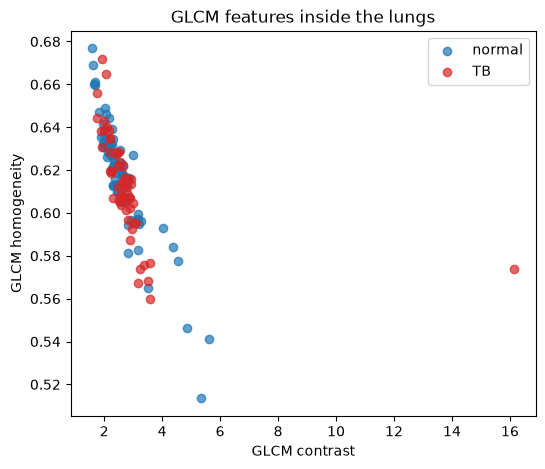

In [22]:
# try other pairs from GLCM_PROPS
x_feat, y_feat = 'contrast', 'homogeneity'

plt.figure(figsize=(6, 5))

for label, colour, text in [(0, 'tab:blue', 'normal'), (1, 'tab:red', 'TB')]:
    subset = features[features['label'] == label]
    plt.scatter(subset[x_feat], subset[y_feat], c=colour, label=text, alpha=0.7)

plt.xlabel(f'GLCM {x_feat}')
plt.ylabel(f'GLCM {y_feat}')
plt.title('GLCM features inside the lungs')
plt.legend()
plt.savefig('figures/fig_4_glcm_scatter.pdf', bbox_inches='tight')
plt.show()

Then, for every feature, the median in each class and a Mann-Whitney U test. Since I run 5 tests,
I also apply a Bonferroni correction (multiply each p-value by 5) to account for multiple comparisons.

In [23]:
stats = []

for feat in GLCM_PROPS:

    normal_vals = features.loc[features['label'] == 0, feat]
    tb_vals     = features.loc[features['label'] == 1, feat]
    p           = mannwhitneyu(normal_vals, tb_vals).pvalue

    stats.append({
        'feature'           : feat,
        'median normal'     : normal_vals.median(),
        'median TB'         : tb_vals.median(),
        'p-value'           : p,
        'p-value (Bonf.)'   : min(1.0, p * len(GLCM_PROPS)),
    })

pd.DataFrame(stats).round(4)

,feature,median normal,median TB,p-value,p-value (Bonf.)
0,contrast,2.3875,2.5995,0.0704,0.3519
1,dissimilarity,0.9958,1.0359,0.0658,0.3291
2,homogeneity,0.6215,0.6136,0.0597,0.2986
3,energy,0.1293,0.1248,0.0204,0.1021
4,correlation,0.9617,0.9585,0.9090,1.0000


#### Classifier

I use logistic regression, as in the classification practical:

- `StandardScaler` puts every feature on the same scale (mean 0, standard deviation 1), which logistic
  regression needs because the features have very different ranges;
- with only 138 images, a single train / test split would leave very few test cases, so I use
  **stratified 5-fold cross-validation**: the model trains on 4/5 of the data and predicts the
  remaining 1/5, rotating 5 times so that every image is predicted by a model that never saw it.
  *Stratified* means each fold keeps the same normal / TB ratio.

In [24]:
# inputs: one row per image, one column per feature, targets: 0 / 1
X = features[GLCM_PROPS].values
y = features['label'].values

model = make_pipeline(StandardScaler(), LogisticRegression())
cv    = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

# out-of-fold predicted labels and probabilities of TB
y_pred = cross_val_predict(model, X, y, cv=cv)
y_prob = cross_val_predict(model, X, y, cv=cv, method='predict_proba')[:, 1]

print(classification_report(y, y_pred, target_names=['normal', 'TB']))
print('Confusion matrix (rows = truth, columns = prediction):')
print(confusion_matrix(y, y_pred))
print(f'\nROC AUC: {roc_auc_score(y, y_prob):.3f}  (0.5 = guessing, 1.0 = perfect)')

              precision    recall  f1-score   support

      normal       0.62      0.85      0.72        80
          TB       0.59      0.29      0.39        58

    accuracy                           0.62       138
   macro avg       0.61      0.57      0.56       138
weighted avg       0.61      0.62      0.58       138

Confusion matrix (rows = truth, columns = prediction):
[[68 12]
 [41 17]]

ROC AUC: 0.653  (0.5 = guessing, 1.0 = perfect)


To judge these numbers, the baseline is always guessing "normal", which gives 80 / 138 ≈ 58% accuracy
but misses every TB case. For screening, the **recall for TB** (sensitivity) matters most, since a
missed TB case is worse than a false alarm.

Limitations of this classifier: the data set is small, averaging texture over the whole lung dilutes
small lesions, and the GLCM settings (`levels`, distances) were not tuned.

## Summary and Slide Plan

| Slide | Content | Figures / results from this notebook |
|---|---|---|
| 1. Background & motivation | data set, aims 1–4 | `fig_1_examples.pdf` |
| 2. Results: segmentation | threshold comparison, effect of post-processing | `fig_2_histogram.pdf`, `fig_3_pipeline_steps.pdf`, Dice summary table |
| 3. Results: normal vs TB | segmentation quality per class, GLCM + classifier | `fig_3_dice_boxplot.pdf`, `fig_4_glcm_scatter.pdf`, classification report |
| 4. Failures | worst cases and why they fail | `fig_3_failures.pdf` |